# Sample figures for paper

In [67]:
# Imports
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
from scipy import stats

## One-shot test


### Comparison of RAG vs no Rag for each model

In [68]:
model_names = ["model_1", "model_2", "model_3", "model_4", "model_5", "model_6", "model_7", "model_8", "model_9", "model_10"]
data = {"no_rag": [74.8, 66, 60.6, 56.5, 63.9, 64.5, 56, 58.3, 57.3, 67.5], "rag": [86.9, 74.0, 75.4, 61, 71.3, 65.1, 70.5, 66.7, 61.1, 68.3]}
colors = ["b", "r"]
markers = ["o", "v", "^", "<", ">", "s", "x", "*", "H", "D"]

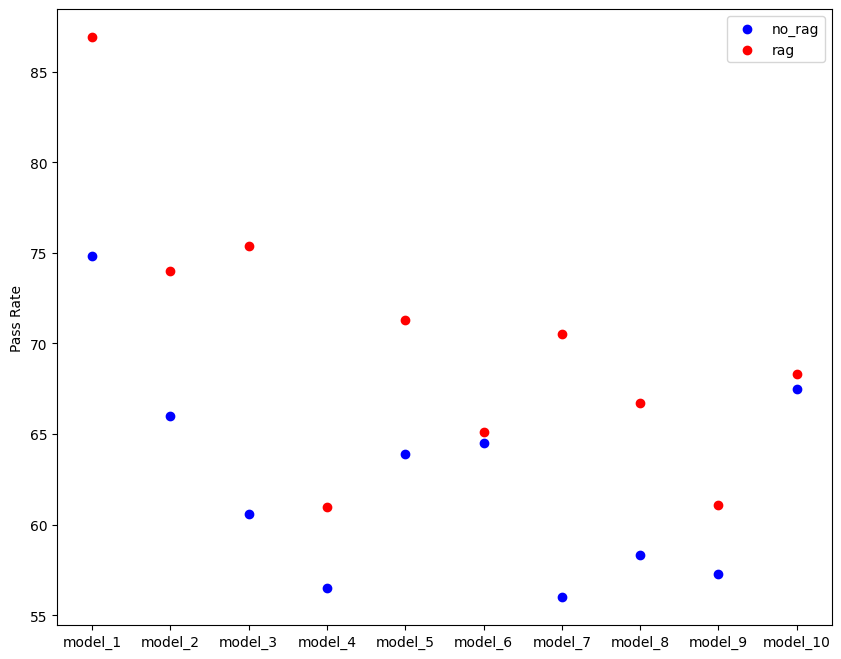

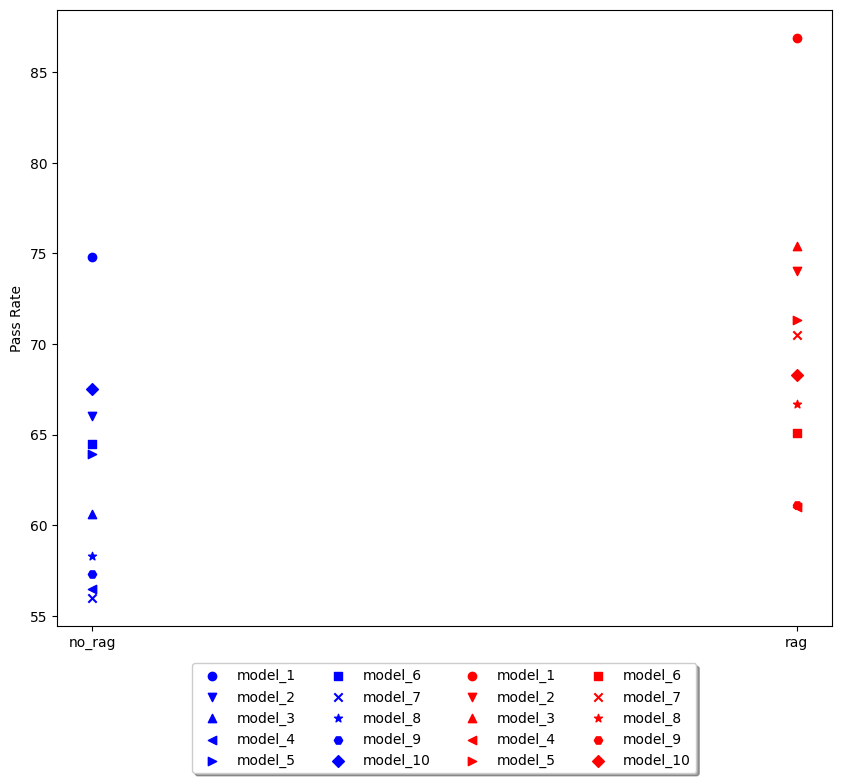

In [69]:
fig1 = plt.figure(figsize=(10, 8))
for i in range(len(data.keys())):
    for j in range(len(model_names)):
        if (j==0):
            plt.scatter(model_names[j], data[list(data.keys())[i]][j], label=list(data.keys())[i], c=colors[i])
        else:
            plt.scatter(model_names[j], data[list(data.keys())[i]][j], c=colors[i])
plt.legend()
plt.ylabel("Pass Rate")
plt.show(fig1)

fig2 = plt.figure(figsize=(10, 8))
for i in range(len(data.keys())):
    for j in range(len(model_names)):
        plt.scatter(list(data.keys())[i], data[list(data.keys())[i]][j], label=model_names[j], marker=markers[j], c=colors[i])
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05),
          fancybox=True, shadow=True, ncol=4) # Would like to remove the duplicates from the legend
plt.ylabel("Pass Rate")
plt.show(fig2)


In [70]:
import numpy as np

# Generate more realistic RAG data where results vary
model_data_rag = {}

# Set seed for reproducibility
np.random.seed(42)

# Define different RAG impact profiles for different models
rag_profiles = {
    # Expensive models - mixed results
    "Claude Sonnet 4.5": "slight_improvement",  # +2 to +5%
    "GPT-5": "moderate_improvement",            # +5 to +10%
    "Gemini 2.5 Pro": "slight_worse",           # -2 to +2%
    "Grok 4": "no_change",                      # -1 to +3%
    
    # Budget models - more varied
    "GPT-4.1 Mini": "significant_improvement",  # +7 to +12%
    "Gemini 2.5 Flash": "moderate_worse",       # -5 to -2%
    "Deepseek R1": "slight_improvement",        # +2 to +6%
    "Deepseek V3": "slight_worse",              # -3 to +1%
    "Qwen3 Coder 480B A35B": "moderate_improvement",  # +5 to +9%
    "Grok Code Fast 1": "no_change"            # -2 to +2%
}

# Generate RAG data based on profiles
for model_name, no_rag_data in model_data.items():
    profile = rag_profiles[model_name]
    rag_data = []
    
    for k in range(5):
        trial = []
        for n in range(5):
            base_value = no_rag_data[k][n]
            
            # Apply different improvement ranges based on profile
            if profile == "significant_improvement":
                change = np.random.randint(7, 13)
            elif profile == "moderate_improvement":
                change = np.random.randint(5, 11)
            elif profile == "slight_improvement":
                change = np.random.randint(2, 7)
            elif profile == "no_change":
                change = np.random.randint(-2, 4)
            elif profile == "slight_worse":
                change = np.random.randint(-3, 3)
            elif profile == "moderate_worse":
                change = np.random.randint(-5, -1)
            else:
                change = 0
            
            rag_value = max(0, min(100, base_value + change))
            trial.append(rag_value)
        rag_data.append(trial)
    
    model_data_rag[model_name] = rag_data

# Print summary of one-shot (n=1, k=1) results
print("One-Shot RAG Impact Summary (n=1, k=1):")
print("=" * 70)
for model_name in model_data.keys():
    no_rag_val = model_data[model_name][0][0]
    rag_val = model_data_rag[model_name][0][0]
    diff = rag_val - no_rag_val
    
    if diff > 0:
        direction = f"✓ +{diff}%"
        symbol = "↑"
    elif diff < 0:
        direction = f"✗ {diff}%"
        symbol = "↓"
    else:
        direction = "→ No change"
        symbol = "→"
    
    print(f"{model_name:30s} {symbol} No RAG: {no_rag_val}% | RAG: {rag_val}% | {direction}")

print("\n" + "=" * 70)


One-Shot RAG Impact Summary (n=1, k=1):
Claude Sonnet 4.5              ↑ No RAG: 68% | RAG: 73% | ✓ +5%
GPT-5                          ↑ No RAG: 66% | RAG: 73% | ✓ +7%
Gemini 2.5 Pro                 ↓ No RAG: 64% | RAG: 62% | ✗ -2%
Grok 4                         ↓ No RAG: 61% | RAG: 60% | ✗ -1%
GPT-4.1 Mini                   ↑ No RAG: 58% | RAG: 65% | ✓ +7%
Gemini 2.5 Flash               ↓ No RAG: 55% | RAG: 50% | ✗ -5%
Deepseek R1                    ↑ No RAG: 52% | RAG: 54% | ✓ +2%
Deepseek V3                    → No RAG: 49% | RAG: 49% | → No change
Qwen3 Coder 480B A35B          ↑ No RAG: 53% | RAG: 61% | ✓ +8%
Grok Code Fast 1               ↓ No RAG: 50% | RAG: 49% | ✗ -1%



Generating One-Shot Comparison Visualizations...

✓ Option 1: Grouped Bar Chart saved
✓ Option 2: Dot Plot saved
✓ Option 3: Split by Category saved
✓ Option 4: Improvement Chart saved


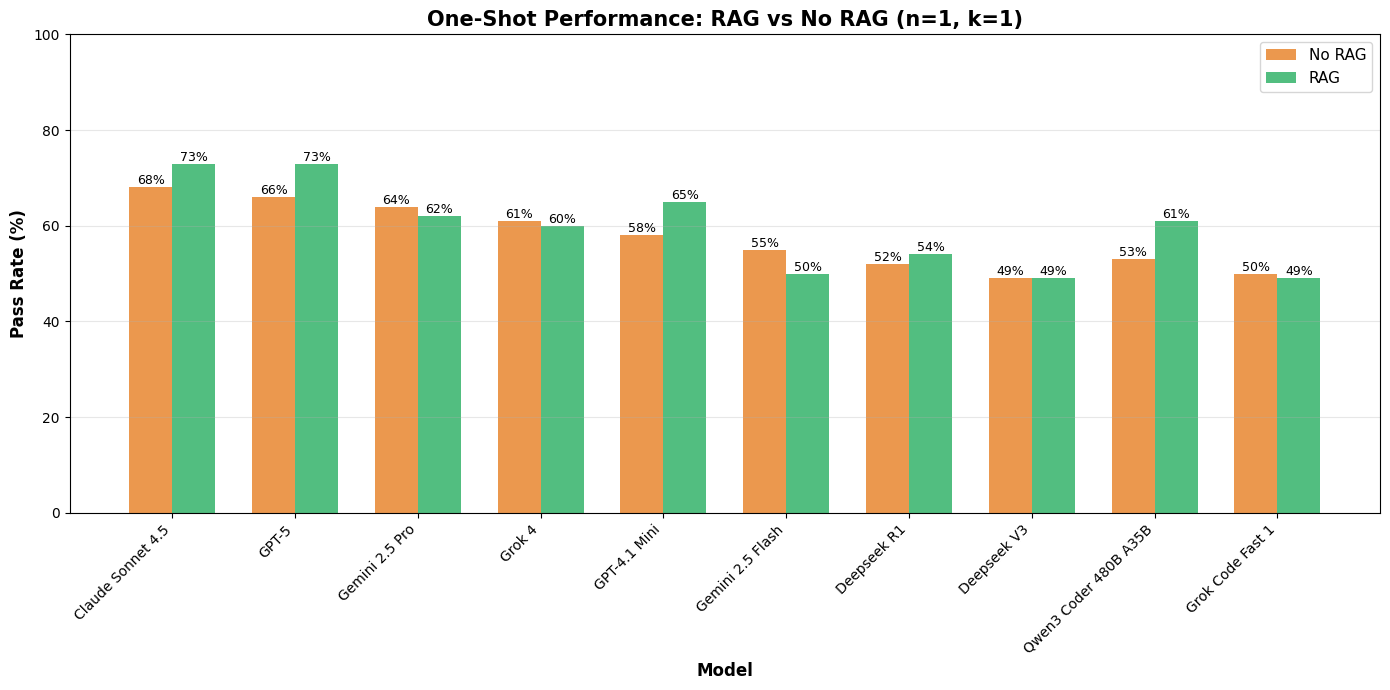

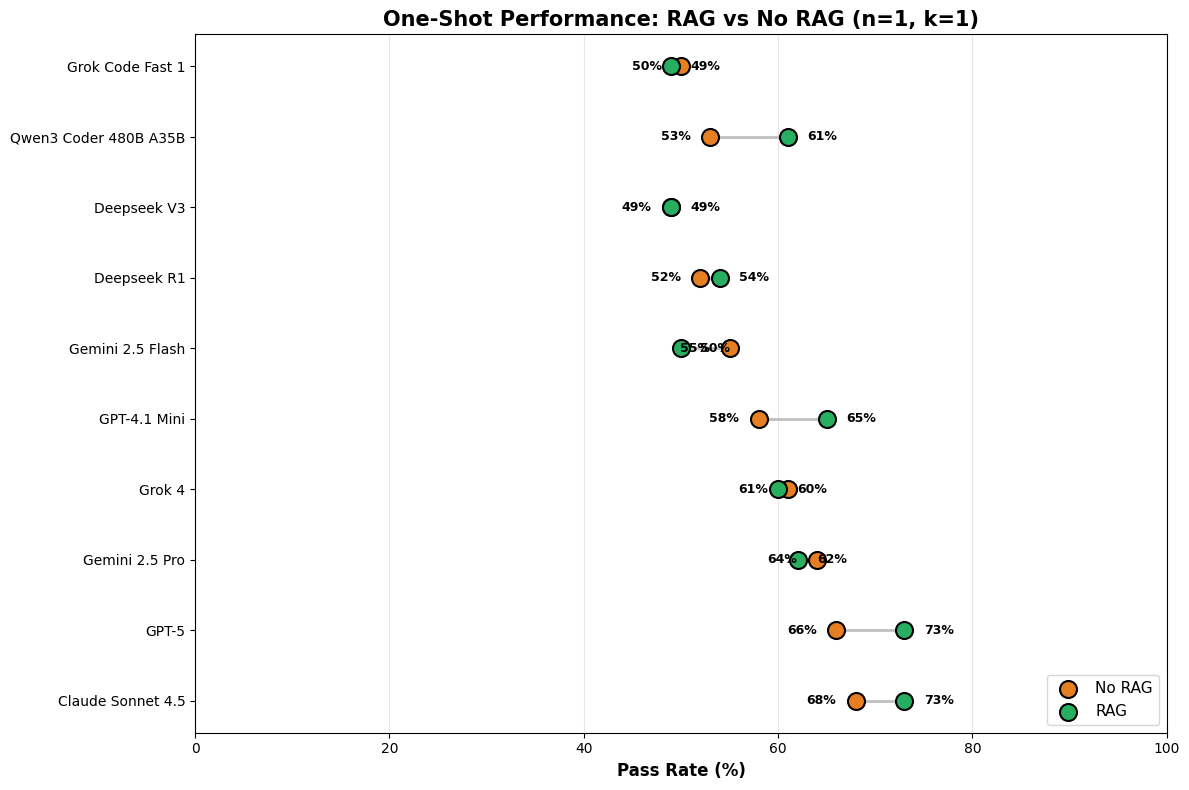

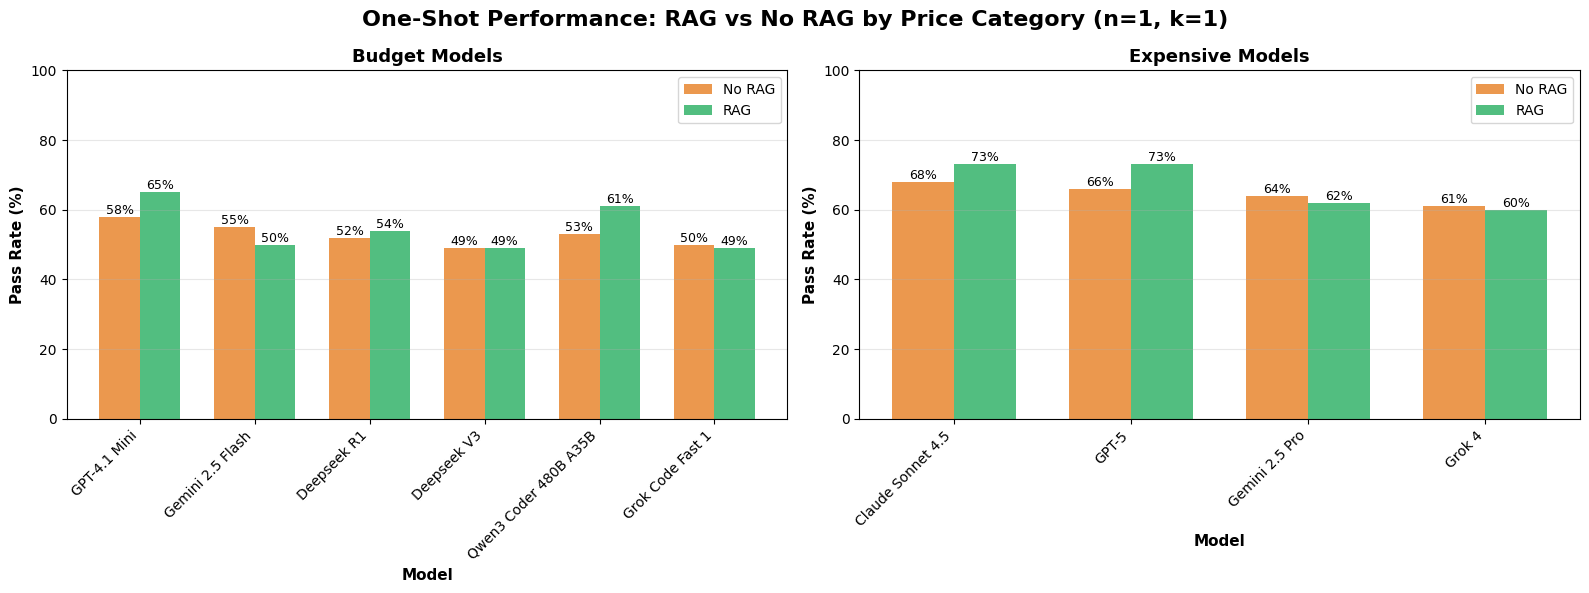

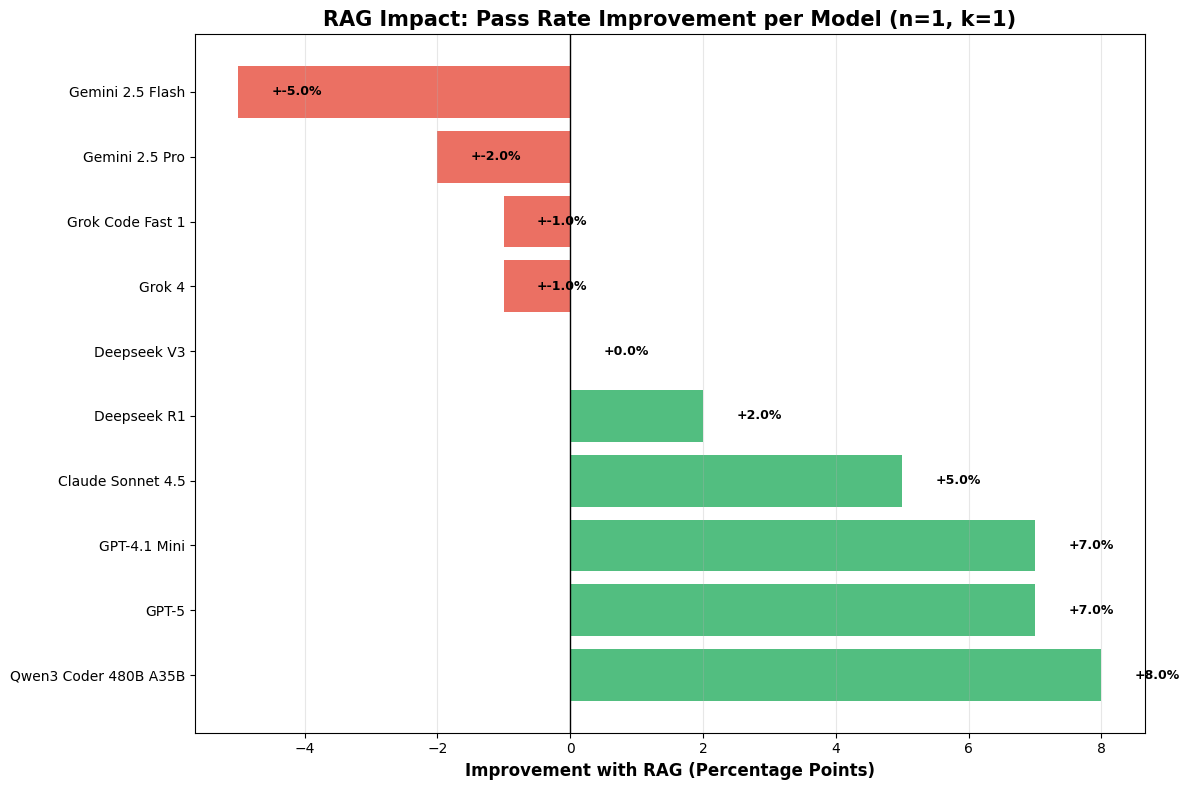

In [71]:
import matplotlib.pyplot as plt
import numpy as np

# ===== OPTION 1: Grouped Bar Chart (RECOMMENDED) =====
def plot_oneshot_bar_comparison(model_data_no_rag, model_data_rag):
    """
    Grouped bar chart comparing RAG vs No RAG for one-shot trials.
    Best for direct model-by-model comparison.
    """
    # Extract n=1, k=1 data (first iteration, first trial)
    models = list(model_data_no_rag.keys())
    no_rag_values = [model_data_no_rag[model][0][0] for model in models]
    rag_values = [model_data_rag[model][0][0] for model in models]
    
    x = np.arange(len(models))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=(14, 7))
    
    bars1 = ax.bar(x - width/2, no_rag_values, width, label='No RAG', 
                   color='#E67E22', alpha=0.8)
    bars2 = ax.bar(x + width/2, rag_values, width, label='RAG', 
                   color='#27AE60', alpha=0.8)
    
    # Add value labels on bars
    for bar in bars1:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
               f'{height:.0f}%', ha='center', va='bottom', fontsize=9)
    
    for bar in bars2:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
               f'{height:.0f}%', ha='center', va='bottom', fontsize=9)
    
    ax.set_xlabel('Model', fontsize=12, fontweight='bold')
    ax.set_ylabel('Pass Rate (%)', fontsize=12, fontweight='bold')
    ax.set_title('One-Shot Performance: RAG vs No RAG (n=1, k=1)', 
                 fontsize=15, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=45, ha='right')
    ax.legend(fontsize=11)
    ax.set_ylim(0, 100)
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    return plt


# ===== OPTION 2: Dot Plot with Improvement Lines =====
def plot_oneshot_dot_comparison(model_data_no_rag, model_data_rag):
    """
    Dot plot showing No RAG and RAG with lines connecting them.
    Best for showing improvement magnitude.
    """
    models = list(model_data_no_rag.keys())
    no_rag_values = [model_data_no_rag[model][0][0] for model in models]
    rag_values = [model_data_rag[model][0][0] for model in models]
    
    fig, ax = plt.subplots(figsize=(12, 8))
    y_pos = np.arange(len(models))
    
    # Draw lines connecting No RAG to RAG
    for i in range(len(models)):
        ax.plot([no_rag_values[i], rag_values[i]], [y_pos[i], y_pos[i]], 
               color='gray', linewidth=2, alpha=0.5, zorder=1)
    
    # Plot points
    ax.scatter(no_rag_values, y_pos, s=150, color='#E67E22', 
              label='No RAG', zorder=3, edgecolors='black', linewidth=1.5)
    ax.scatter(rag_values, y_pos, s=150, color='#27AE60', 
              label='RAG', zorder=3, edgecolors='black', linewidth=1.5)
    
    # Add value labels
    for i, (no_rag, rag) in enumerate(zip(no_rag_values, rag_values)):
        ax.text(no_rag - 2, y_pos[i], f'{no_rag:.0f}%', 
               ha='right', va='center', fontsize=9, fontweight='bold')
        ax.text(rag + 2, y_pos[i], f'{rag:.0f}%', 
               ha='left', va='center', fontsize=9, fontweight='bold')
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(models, fontsize=10)
    ax.set_xlabel('Pass Rate (%)', fontsize=12, fontweight='bold')
    ax.set_title('One-Shot Performance: RAG vs No RAG (n=1, k=1)', 
                fontsize=15, fontweight='bold')
    ax.legend(fontsize=11, loc='lower right')
    ax.set_xlim(0, 100)
    ax.grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    return plt


# ===== OPTION 3: Split by Category Bar Chart =====
def plot_oneshot_by_category(model_data_no_rag, model_data_rag, 
                             budget_models, expensive_models):
    """
    Two subplots comparing budget vs expensive models.
    Best for analyzing price tier differences.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    width = 0.35
    
    # Budget models
    budget_no_rag = [model_data_no_rag[m][0][0] for m in budget_models]
    budget_rag = [model_data_rag[m][0][0] for m in budget_models]
    x1 = np.arange(len(budget_models))
    
    bars1 = ax1.bar(x1 - width/2, budget_no_rag, width, label='No RAG', 
                    color='#E67E22', alpha=0.8)
    bars2 = ax1.bar(x1 + width/2, budget_rag, width, label='RAG', 
                    color='#27AE60', alpha=0.8)
    
    for bar in bars1 + bars2:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.0f}%', ha='center', va='bottom', fontsize=9)
    
    ax1.set_xlabel('Model', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Pass Rate (%)', fontsize=11, fontweight='bold')
    ax1.set_title('Budget Models', fontsize=13, fontweight='bold')
    ax1.set_xticks(x1)
    ax1.set_xticklabels(budget_models, rotation=45, ha='right')
    ax1.legend(fontsize=10)
    ax1.set_ylim(0, 100)
    ax1.grid(axis='y', alpha=0.3)
    
    # Expensive models
    expensive_no_rag = [model_data_no_rag[m][0][0] for m in expensive_models]
    expensive_rag = [model_data_rag[m][0][0] for m in expensive_models]
    x2 = np.arange(len(expensive_models))
    
    bars3 = ax2.bar(x2 - width/2, expensive_no_rag, width, label='No RAG', 
                    color='#E67E22', alpha=0.8)
    bars4 = ax2.bar(x2 + width/2, expensive_rag, width, label='RAG', 
                    color='#27AE60', alpha=0.8)
    
    for bar in bars3 + bars4:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.0f}%', ha='center', va='bottom', fontsize=9)
    
    ax2.set_xlabel('Model', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Pass Rate (%)', fontsize=11, fontweight='bold')
    ax2.set_title('Expensive Models', fontsize=13, fontweight='bold')
    ax2.set_xticks(x2)
    ax2.set_xticklabels(expensive_models, rotation=45, ha='right')
    ax2.legend(fontsize=10)
    ax2.set_ylim(0, 100)
    ax2.grid(axis='y', alpha=0.3)
    
    plt.suptitle('One-Shot Performance: RAG vs No RAG by Price Category (n=1, k=1)', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    return plt


# ===== OPTION 4: Difference/Improvement Bar Chart =====
def plot_oneshot_improvement(model_data_no_rag, model_data_rag):
    """
    Bar chart showing the improvement from RAG (difference between RAG and No RAG).
    Best for highlighting RAG's impact.
    """
    models = list(model_data_no_rag.keys())
    no_rag_values = [model_data_no_rag[model][0][0] for model in models]
    rag_values = [model_data_rag[model][0][0] for model in models]
    improvements = [rag - no_rag for rag, no_rag in zip(rag_values, no_rag_values)]
    
    # Sort by improvement
    sorted_data = sorted(zip(models, improvements, no_rag_values, rag_values), 
                        key=lambda x: x[1], reverse=True)
    models_sorted = [x[0] for x in sorted_data]
    improvements_sorted = [x[1] for x in sorted_data]
    
    fig, ax = plt.subplots(figsize=(12, 8))
    y_pos = np.arange(len(models_sorted))
    
    colors = ['#27AE60' if imp > 0 else '#E74C3C' for imp in improvements_sorted]
    bars = ax.barh(y_pos, improvements_sorted, color=colors, alpha=0.8)
    
    # Add value labels
    for i, (bar, imp) in enumerate(zip(bars, improvements_sorted)):
        width = bar.get_width()
        ax.text(width + 0.5, bar.get_y() + bar.get_height()/2.,
               f'+{imp:.1f}%', ha='left', va='center', fontsize=9, fontweight='bold')
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(models_sorted, fontsize=10)
    ax.set_xlabel('Improvement with RAG (Percentage Points)', fontsize=12, fontweight='bold')
    ax.set_title('RAG Impact: Pass Rate Improvement per Model (n=1, k=1)', 
                fontsize=15, fontweight='bold')
    ax.axvline(x=0, color='black', linewidth=1, linestyle='-')
    ax.grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    return plt


# Generate all visualizations
print("Generating One-Shot Comparison Visualizations...\n")

fig1 = plot_oneshot_bar_comparison(model_data, model_data_rag)
fig1.savefig('oneshot_bar_comparison.png', dpi=300, bbox_inches='tight')
print("✓ Option 1: Grouped Bar Chart saved")

fig2 = plot_oneshot_dot_comparison(model_data, model_data_rag)
fig2.savefig('oneshot_dot_comparison.png', dpi=300, bbox_inches='tight')
print("✓ Option 2: Dot Plot saved")

budget_models = ["GPT-4.1 Mini", "Gemini 2.5 Flash", "Deepseek R1", 
                 "Deepseek V3", "Qwen3 Coder 480B A35B", "Grok Code Fast 1"]
expensive_models = ["Claude Sonnet 4.5", "GPT-5", "Gemini 2.5 Pro", "Grok 4"]

fig3 = plot_oneshot_by_category(model_data, model_data_rag, budget_models, expensive_models)
fig3.savefig('oneshot_by_category.png', dpi=300, bbox_inches='tight')
print("✓ Option 3: Split by Category saved")

fig4 = plot_oneshot_improvement(model_data, model_data_rag)
fig4.savefig('oneshot_improvement.png', dpi=300, bbox_inches='tight')
print("✓ Option 4: Improvement Chart saved")

plt.show()


Generating Vitis vs DynaRapid Comparison Visualizations...

✓ Option 1: Side-by-Side Bar Chart saved
✓ Option 2: Line Plot with Iterations saved
✓ Option 3: Toolchain Difference (FIXED) saved
✓ Option 4: Split by Price Category saved


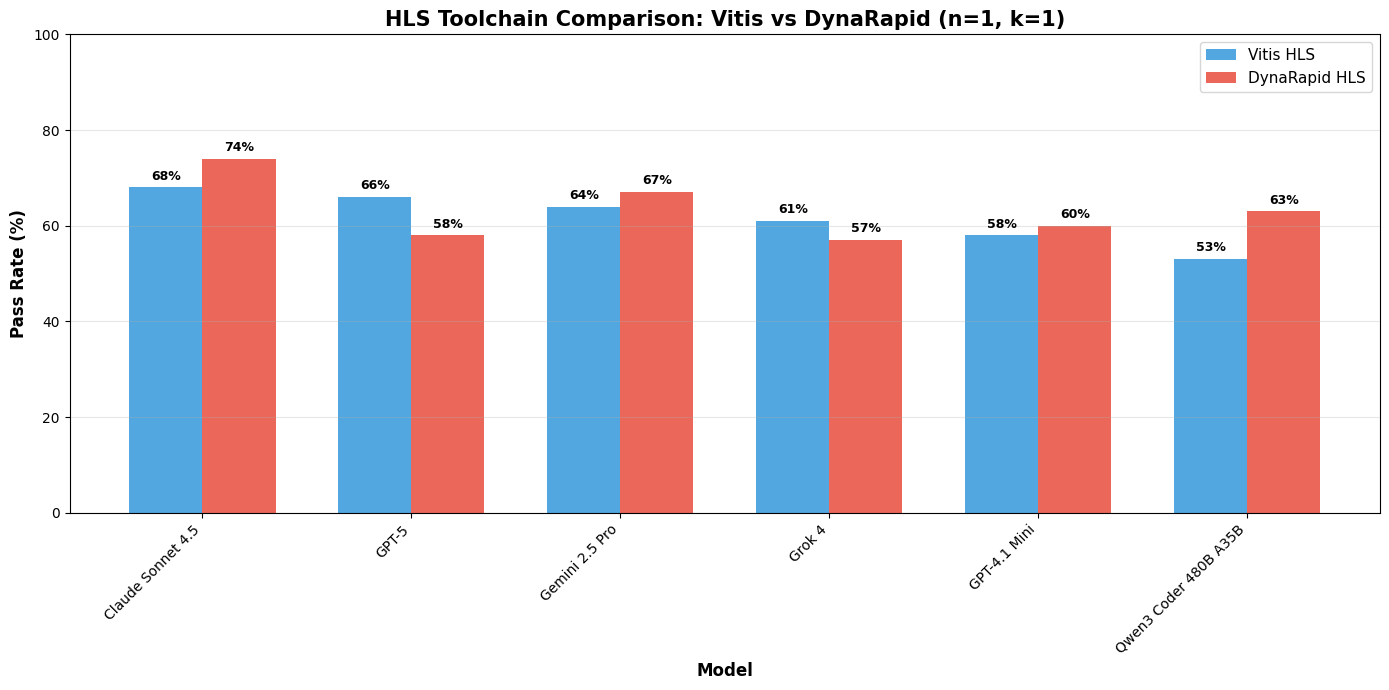

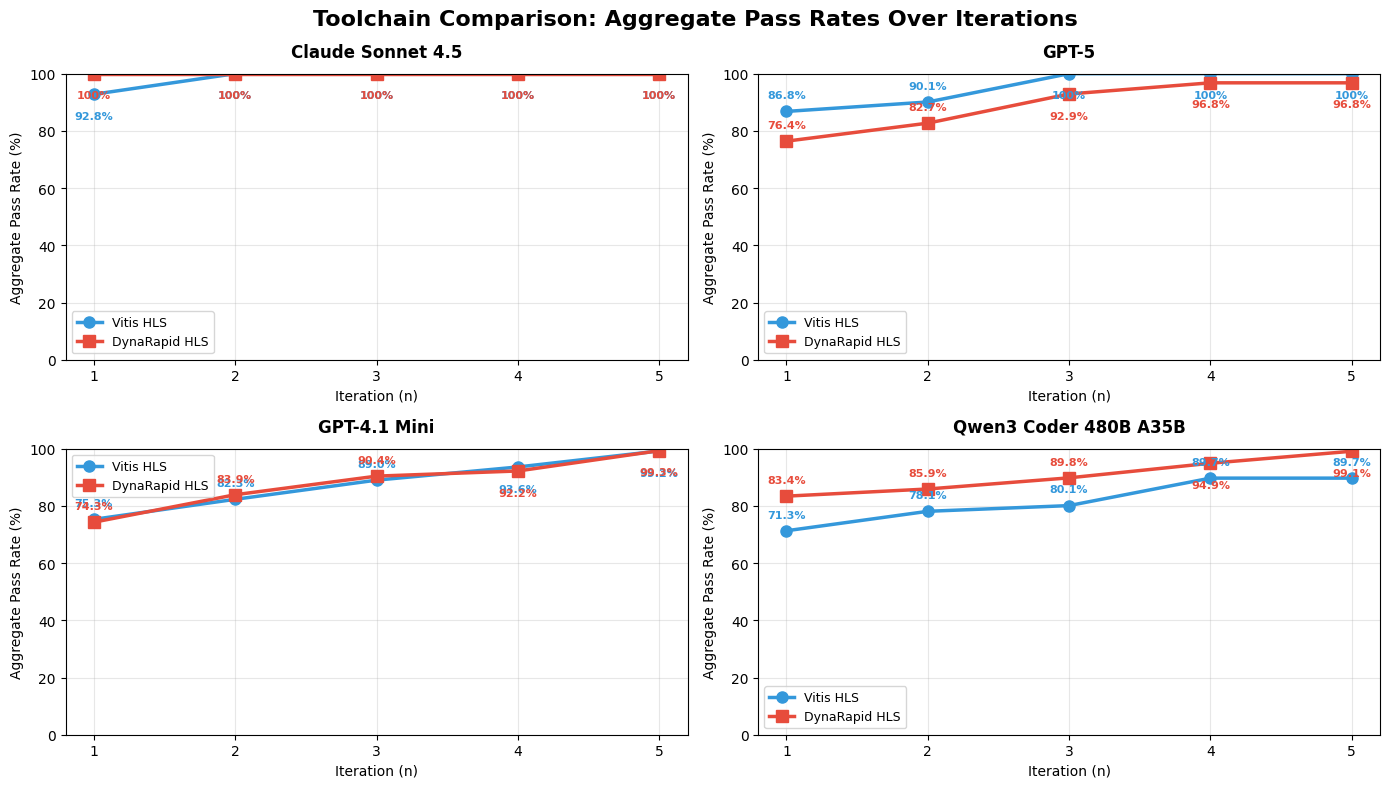

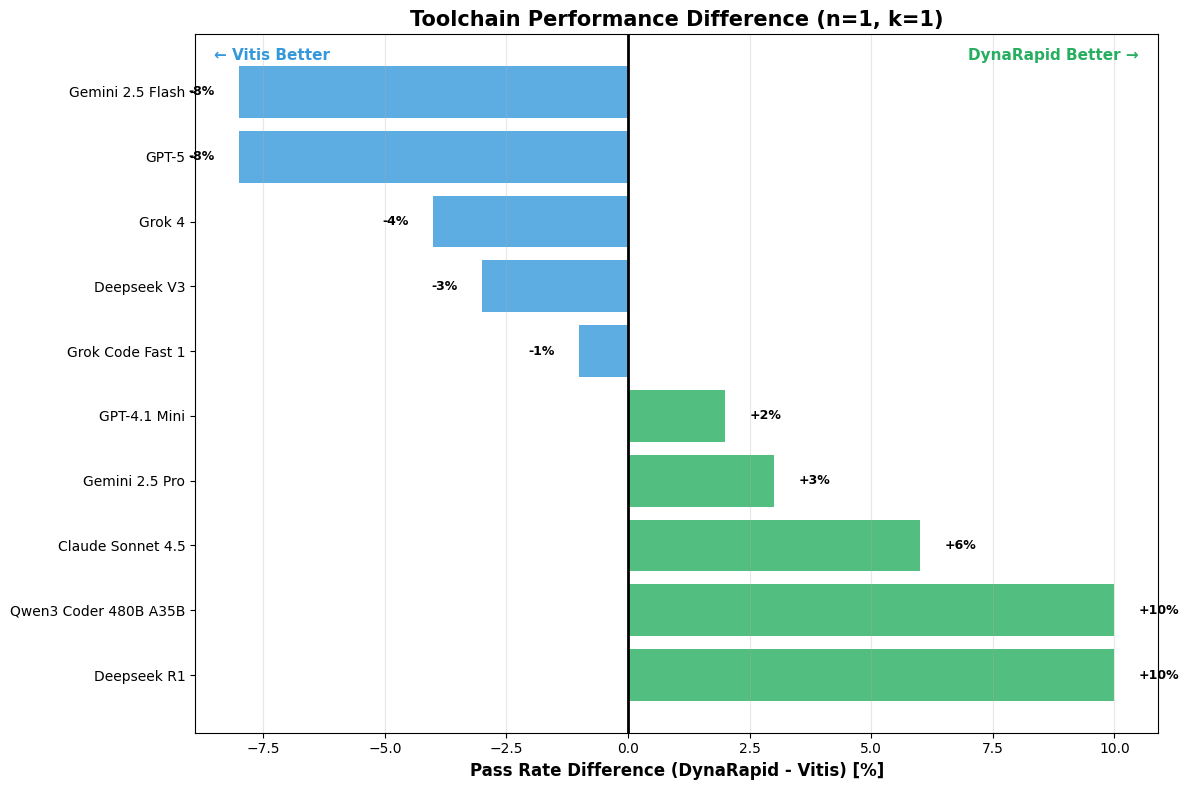

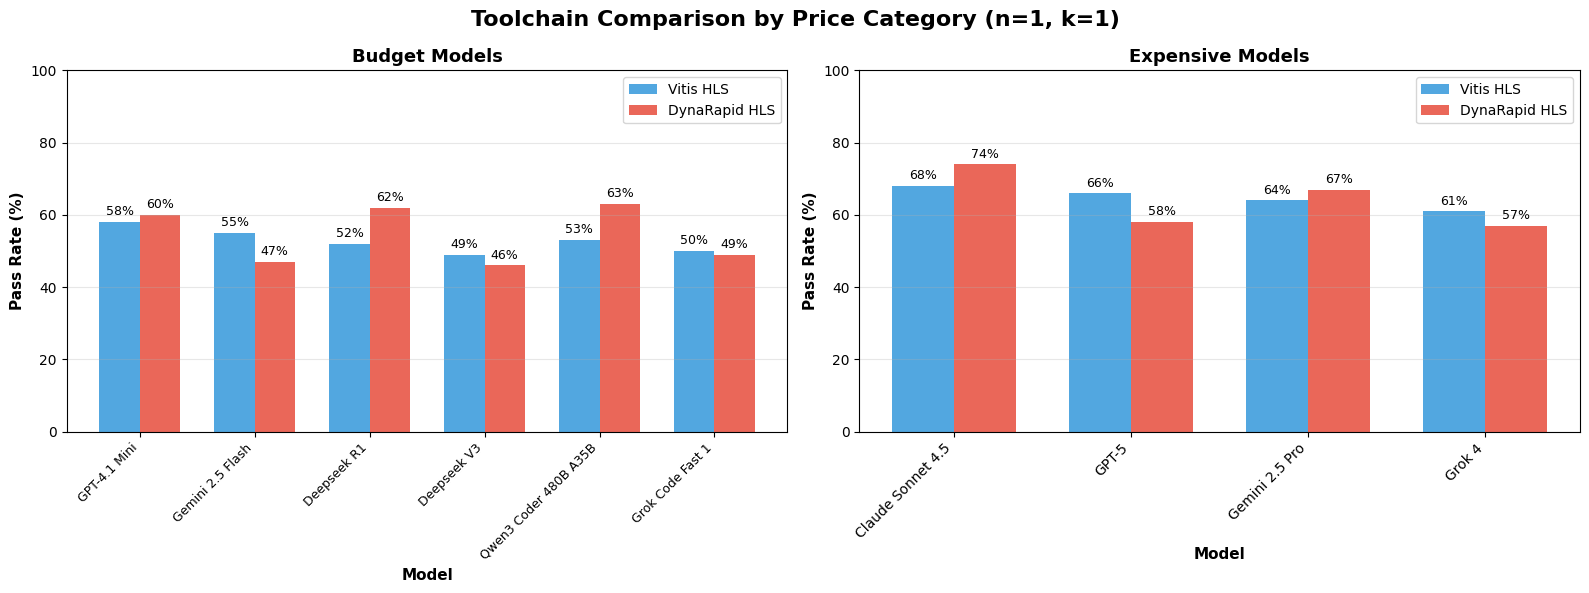


Toolchain Comparison Summary (n=1, k=1):
Claude Sonnet 4.5              ✓ Vitis:  68% | DynaRapid:  74% | Diff:  +6% | Better: DynaRapid
GPT-5                          ✓ Vitis:  66% | DynaRapid:  58% | Diff:  -8% | Better: Vitis
Gemini 2.5 Pro                 ✓ Vitis:  64% | DynaRapid:  67% | Diff:  +3% | Better: DynaRapid
Grok 4                         ✓ Vitis:  61% | DynaRapid:  57% | Diff:  -4% | Better: Vitis
GPT-4.1 Mini                   ✓ Vitis:  58% | DynaRapid:  60% | Diff:  +2% | Better: DynaRapid
Gemini 2.5 Flash               ✓ Vitis:  55% | DynaRapid:  47% | Diff:  -8% | Better: Vitis
Deepseek R1                    ✓ Vitis:  52% | DynaRapid:  62% | Diff: +10% | Better: DynaRapid
Deepseek V3                    ✓ Vitis:  49% | DynaRapid:  46% | Diff:  -3% | Better: Vitis
Qwen3 Coder 480B A35B          ✓ Vitis:  53% | DynaRapid:  63% | Diff: +10% | Better: DynaRapid
Grok Code Fast 1               ✓ Vitis:  50% | DynaRapid:  49% | Diff:  -1% | Better: Vitis


In [72]:
import matplotlib.pyplot as plt
import numpy as np

# Generate more realistic Vitis vs DynaRapid data
# Some models do better with Vitis, some with DynaRapid

np.random.seed(789)

model_data_dynarapid = {}
dynarapid_profiles = {
    # Some models do better with DynaRapid
    "Claude Sonnet 4.5": "dynarapid_better",    # +3 to +8%
    "Deepseek R1": "dynarapid_better",          # +5 to +10%
    "Qwen3 Coder 480B A35B": "dynarapid_better", # +4 to +9%
    
    # Some models do better with Vitis
    "GPT-5": "vitis_better",                    # -5 to -10%
    "Gemini 2.5 Flash": "vitis_better",         # -7 to -12%
    "Grok 4": "vitis_better",                   # -4 to -8%
    
    # Some models perform similarly
    "Gemini 2.5 Pro": "similar",                # -2 to +3%
    "GPT-4.1 Mini": "similar",                  # -3 to +2%
    "Deepseek V3": "similar",                   # -2 to +2%
    "Grok Code Fast 1": "similar"               # -1 to +3%
}

for model_name, vitis_data in model_data.items():
    profile = dynarapid_profiles[model_name]
    dynarapid_data = []
    
    for k in range(5):
        trial = []
        for n in range(5):
            vitis_value = vitis_data[k][n]
            
            # Apply different changes based on profile
            if profile == "dynarapid_better":
                change = np.random.randint(3, 11)
            elif profile == "vitis_better":
                change = np.random.randint(-12, -3)
            else:  # similar
                change = np.random.randint(-3, 4)
            
            dynarapid_value = max(15, min(100, vitis_value + change))
            trial.append(dynarapid_value)
        dynarapid_data.append(trial)
    
    model_data_dynarapid[model_name] = dynarapid_data


# ===== OPTION 1: Side-by-Side Grouped Bar Chart =====
def plot_vitis_vs_dynarapid_bar(model_data_vitis, model_data_dynarapid, 
                                 selected_models=None):
    """
    Grouped bar chart comparing Vitis HLS vs DynaRapid HLS.
    Shows one-shot (n=1, k=1) performance.
    """
    if selected_models is None:
        models = list(model_data_vitis.keys())
    else:
        models = selected_models
    
    # Extract n=1, k=1 data
    vitis_values = [model_data_vitis[model][0][0] for model in models]
    dynarapid_values = [model_data_dynarapid[model][0][0] for model in models]
    
    x = np.arange(len(models))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=(14, 7))
    
    bars1 = ax.bar(x - width/2, vitis_values, width, label='Vitis HLS', 
                   color='#3498DB', alpha=0.85)
    bars2 = ax.bar(x + width/2, dynarapid_values, width, label='DynaRapid HLS', 
                   color='#E74C3C', alpha=0.85)
    
    # Add value labels on bars
    for bar in bars1:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 1,
               f'{height:.0f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    for bar in bars2:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 1,
               f'{height:.0f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax.set_xlabel('Model', fontsize=12, fontweight='bold')
    ax.set_ylabel('Pass Rate (%)', fontsize=12, fontweight='bold')
    ax.set_title('HLS Toolchain Comparison: Vitis vs DynaRapid (n=1, k=1)', 
                 fontsize=15, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=45, ha='right')
    ax.legend(fontsize=11, loc='upper right')
    ax.set_ylim(0, 100)
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    return plt


# ===== OPTION 2: Aggregate Pass Rates Over Iterations =====
def plot_vitis_vs_dynarapid_lines(model_data_vitis, model_data_dynarapid,
                                   selected_models=None):
    """
    Line plot showing aggregate pass rates over iterations for both toolchains.
    """
    if selected_models is None:
        selected_models = list(model_data_vitis.keys())[:4]
    
    n_models = len(selected_models)
    ncols = 2
    nrows = (n_models + ncols - 1) // ncols
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4*nrows))
    axes = axes.flatten() if n_models > 1 else [axes]
    iterations = np.arange(1, 6)
    
    for idx, model_name in enumerate(selected_models):
        # Calculate aggregates
        vitis_aggregate = calculate_aggregate_pass_rate_random(
            model_data_vitis[model_name], seed=idx
        )
        dynarapid_aggregate = calculate_aggregate_pass_rate_random(
            model_data_dynarapid[model_name], seed=idx
        )
        
        # Plot Vitis
        axes[idx].plot(iterations, vitis_aggregate, marker='o', linewidth=2.5,
                      markersize=8, label='Vitis HLS', color='#3498DB')
        
        # Plot DynaRapid
        axes[idx].plot(iterations, dynarapid_aggregate, marker='s', linewidth=2.5,
                      markersize=8, label='DynaRapid HLS', color='#E74C3C')
        
        # Add value labels
        for i, (v_rate, d_rate) in enumerate(zip(vitis_aggregate, dynarapid_aggregate)):
            if v_rate > 92:
                axes[idx].annotate(f'{v_rate}%', xy=(i+1, v_rate), xytext=(0, -12),
                                 textcoords='offset points', ha='center', va='top',
                                 fontsize=8, fontweight='bold', color='#3498DB')
            else:
                axes[idx].annotate(f'{v_rate}%', xy=(i+1, v_rate), xytext=(0, 8),
                                 textcoords='offset points', ha='center', va='bottom',
                                 fontsize=8, fontweight='bold', color='#3498DB')
            
            if d_rate > 92:
                axes[idx].annotate(f'{d_rate}%', xy=(i+1, d_rate), xytext=(0, -12),
                                 textcoords='offset points', ha='center', va='top',
                                 fontsize=8, fontweight='bold', color='#E74C3C')
            else:
                axes[idx].annotate(f'{d_rate}%', xy=(i+1, d_rate), xytext=(0, 8),
                                 textcoords='offset points', ha='center', va='bottom',
                                 fontsize=8, fontweight='bold', color='#E74C3C')
        
        axes[idx].set_title(model_name, fontsize=12, fontweight='bold', pad=12)
        axes[idx].set_xlabel('Iteration (n)', fontsize=10)
        axes[idx].set_ylabel('Aggregate Pass Rate (%)', fontsize=10)
        axes[idx].legend(loc='best', fontsize=9)
        axes[idx].grid(True, alpha=0.3)
        axes[idx].set_xticks(iterations)
        axes[idx].set_ylim(0, 100)
    
    # Hide extra subplots
    for idx in range(n_models, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Toolchain Comparison: Aggregate Pass Rates Over Iterations', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    return plt


# ===== OPTION 3: Toolchain Preference (FIXED LABELS) =====
def plot_toolchain_difference(model_data_vitis, model_data_dynarapid):
    """
    Horizontal bar chart showing pass rate difference between toolchains.
    Positive = DynaRapid better, Negative = Vitis better.
    FIXED: Labels now positioned correctly relative to bars.
    """
    models = list(model_data_vitis.keys())
    differences = []
    
    for model in models:
        vitis_val = model_data_vitis[model][0][0]
        dynarapid_val = model_data_dynarapid[model][0][0]
        diff = dynarapid_val - vitis_val  # Positive = DynaRapid better
        differences.append(diff)
    
    # Sort by difference
    sorted_data = sorted(zip(models, differences), key=lambda x: x[1], reverse=True)
    models_sorted = [x[0] for x in sorted_data]
    differences_sorted = [x[1] for x in sorted_data]
    
    fig, ax = plt.subplots(figsize=(12, 8))
    y_pos = np.arange(len(models_sorted))
    
    # Color: green if DynaRapid better, blue if Vitis better
    colors = ['#27AE60' if diff > 0 else '#3498DB' for diff in differences_sorted]
    bars = ax.barh(y_pos, differences_sorted, color=colors, alpha=0.8)
    
    # Add value labels - FIXED POSITIONING
    for i, (bar, diff) in enumerate(zip(bars, differences_sorted)):
        width = bar.get_width()
        
        # Position label just outside the bar end
        if width >= 0:
            label_x = width + 0.5  # Positive bars: label to the right
            ha = 'left'
        else:
            label_x = width - 0.5  # Negative bars: label to the left
            ha = 'right'
        
        ax.text(label_x, bar.get_y() + bar.get_height()/2.,
               f'{diff:+.0f}%', ha=ha, va='center', fontsize=9, fontweight='bold')
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(models_sorted, fontsize=10)
    ax.set_xlabel('Pass Rate Difference (DynaRapid - Vitis) [%]', fontsize=12, fontweight='bold')
    ax.set_title('Toolchain Performance Difference (n=1, k=1)', 
                fontsize=15, fontweight='bold')
    ax.axvline(x=0, color='black', linewidth=2, linestyle='-')
    ax.grid(axis='x', alpha=0.3)
    
    # Add annotations
    ax.text(0.98, 0.98, 'DynaRapid Better →', transform=ax.transAxes,
           fontsize=11, verticalalignment='top', horizontalalignment='right',
           color='#27AE60', fontweight='bold')
    ax.text(0.02, 0.98, '← Vitis Better', transform=ax.transAxes,
           fontsize=11, verticalalignment='top', color='#3498DB', fontweight='bold')
    
    plt.tight_layout()
    return plt


# ===== OPTION 4: Split by Price Category =====
def plot_vitis_vs_dynarapid_by_category(model_data_vitis, model_data_dynarapid,
                                         budget_models, expensive_models):
    """
    Two subplots comparing toolchains for budget vs expensive models.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    width = 0.35
    
    # Budget models
    budget_vitis = [model_data_vitis[m][0][0] for m in budget_models]
    budget_dynarapid = [model_data_dynarapid[m][0][0] for m in budget_models]
    x1 = np.arange(len(budget_models))
    
    bars1 = ax1.bar(x1 - width/2, budget_vitis, width, label='Vitis HLS', 
                    color='#3498DB', alpha=0.85)
    bars2 = ax1.bar(x1 + width/2, budget_dynarapid, width, label='DynaRapid HLS', 
                    color='#E74C3C', alpha=0.85)
    
    for bar in bars1 + bars2:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 1,
                f'{height:.0f}%', ha='center', va='bottom', fontsize=9)
    
    ax1.set_xlabel('Model', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Pass Rate (%)', fontsize=11, fontweight='bold')
    ax1.set_title('Budget Models', fontsize=13, fontweight='bold')
    ax1.set_xticks(x1)
    ax1.set_xticklabels(budget_models, rotation=45, ha='right', fontsize=9)
    ax1.legend(fontsize=10)
    ax1.set_ylim(0, 100)
    ax1.grid(axis='y', alpha=0.3)
    
    # Expensive models
    expensive_vitis = [model_data_vitis[m][0][0] for m in expensive_models]
    expensive_dynarapid = [model_data_dynarapid[m][0][0] for m in expensive_models]
    x2 = np.arange(len(expensive_models))
    
    bars3 = ax2.bar(x2 - width/2, expensive_vitis, width, label='Vitis HLS', 
                    color='#3498DB', alpha=0.85)
    bars4 = ax2.bar(x2 + width/2, expensive_dynarapid, width, label='DynaRapid HLS', 
                    color='#E74C3C', alpha=0.85)
    
    for bar in bars3 + bars4:
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 1,
                f'{height:.0f}%', ha='center', va='bottom', fontsize=9)
    
    ax2.set_xlabel('Model', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Pass Rate (%)', fontsize=11, fontweight='bold')
    ax2.set_title('Expensive Models', fontsize=13, fontweight='bold')
    ax2.set_xticks(x2)
    ax2.set_xticklabels(expensive_models, rotation=45, ha='right')
    ax2.legend(fontsize=10)
    ax2.set_ylim(0, 100)
    ax2.grid(axis='y', alpha=0.3)
    
    plt.suptitle('Toolchain Comparison by Price Category (n=1, k=1)', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    return plt


# Generate all options
print("Generating Vitis vs DynaRapid Comparison Visualizations...\n")

top_models = ["Claude Sonnet 4.5", "GPT-5", "Gemini 2.5 Pro", "Grok 4",
              "GPT-4.1 Mini", "Qwen3 Coder 480B A35B"]

fig1 = plot_vitis_vs_dynarapid_bar(model_data, model_data_dynarapid, selected_models=top_models)
fig1.savefig('vitis_vs_dynarapid_bar.png', dpi=300, bbox_inches='tight')
print("✓ Option 1: Side-by-Side Bar Chart saved")

fig2 = plot_vitis_vs_dynarapid_lines(model_data, model_data_dynarapid, 
                                      selected_models=["Claude Sonnet 4.5", "GPT-5", 
                                                      "GPT-4.1 Mini", "Qwen3 Coder 480B A35B"])
fig2.savefig('vitis_vs_dynarapid_lines.png', dpi=300, bbox_inches='tight')
print("✓ Option 2: Line Plot with Iterations saved")

fig3 = plot_toolchain_difference(model_data, model_data_dynarapid)
fig3.savefig('toolchain_difference.png', dpi=300, bbox_inches='tight')
print("✓ Option 3: Toolchain Difference (FIXED) saved")

budget_models = ["GPT-4.1 Mini", "Gemini 2.5 Flash", "Deepseek R1", 
                 "Deepseek V3", "Qwen3 Coder 480B A35B", "Grok Code Fast 1"]
expensive_models = ["Claude Sonnet 4.5", "GPT-5", "Gemini 2.5 Pro", "Grok 4"]

fig4 = plot_vitis_vs_dynarapid_by_category(model_data, model_data_dynarapid,
                                            budget_models, expensive_models)
fig4.savefig('vitis_vs_dynarapid_by_category.png', dpi=300, bbox_inches='tight')
print("✓ Option 4: Split by Price Category saved")

plt.show()

# Print summary
print("\n" + "="*70)
print("Toolchain Comparison Summary (n=1, k=1):")
print("="*70)
for model_name in model_data.keys():
    vitis_val = model_data[model_name][0][0]
    dynarapid_val = model_data_dynarapid[model_name][0][0]
    diff = dynarapid_val - vitis_val
    
    if diff > 0:
        better = "DynaRapid"
        symbol = "✓"
    elif diff < 0:
        better = "Vitis"
        symbol = "✓"
    else:
        better = "Tie"
        symbol = "="
    
    print(f"{model_name:30s} {symbol} Vitis: {vitis_val:3d}% | DynaRapid: {dynarapid_val:3d}% | Diff: {diff:+3d}% | Better: {better}")



### Vitis HLS Test

In [73]:
# Fabricated data for 10 LLM models
# Format: model_name: [[k1], [k2], [k3], [k4], [k5]]
# Each k has 5 values representing n=1 through n=5 iterations

model_data = {
    # === EXPENSIVE MODELS (Generally higher performance) ===
    "Claude Sonnet 4.5": [
        [68, 74, 79, 83, 85],  # k=1
        [72, 78, 82, 85, 87],  # k=2
        [65, 71, 76, 80, 82],  # k=3
        [70, 76, 80, 84, 86],  # k=4
        [67, 73, 78, 81, 83]   # k=5
    ],
    
    "GPT-5": [
        [66, 72, 77, 81, 83],  # k=1
        [70, 75, 80, 83, 85],  # k=2
        [68, 74, 78, 82, 84],  # k=3
        [64, 70, 75, 79, 81],  # k=4
        [69, 74, 79, 82, 84]   # k=5
    ],
    
    "Gemini 2.5 Pro": [
        [64, 70, 75, 79, 81],  # k=1
        [67, 73, 77, 81, 83],  # k=2
        [62, 68, 73, 77, 79],  # k=3
        [66, 71, 76, 80, 82],  # k=4
        [65, 70, 75, 78, 80]   # k=5
    ],
    
    "Grok 4": [
        [61, 67, 72, 76, 78],  # k=1
        [64, 69, 74, 78, 80],  # k=2
        [60, 66, 71, 75, 77],  # k=3
        [63, 68, 73, 76, 79],  # k=4
        [62, 67, 72, 75, 78]   # k=5
    ],
    
    # === BUDGET MODELS (Lower but still decent performance) ===
    "GPT-4.1 Mini": [
        [58, 64, 69, 73, 75],  # k=1
        [61, 66, 71, 75, 77],  # k=2
        [56, 62, 67, 71, 73],  # k=3
        [59, 65, 69, 73, 75],  # k=4
        [57, 63, 68, 71, 74]   # k=5
    ],
    
    "Gemini 2.5 Flash": [
        [55, 61, 66, 70, 72],  # k=1
        [58, 63, 68, 72, 74],  # k=2
        [54, 60, 65, 69, 71],  # k=3
        [57, 62, 67, 70, 73],  # k=4
        [56, 61, 66, 69, 72]   # k=5
    ],
    
    "Deepseek R1": [
        [52, 58, 63, 67, 69],  # k=1
        [55, 60, 65, 69, 71],  # k=2
        [50, 56, 61, 65, 67],  # k=3
        [54, 59, 64, 68, 70],  # k=4
        [53, 58, 63, 66, 69]   # k=5
    ],
    
    "Deepseek V3": [
        [49, 55, 60, 64, 66],  # k=1
        [52, 57, 62, 66, 68],  # k=2
        [48, 54, 59, 63, 65],  # k=3
        [51, 56, 61, 65, 67],  # k=4
        [50, 55, 60, 63, 66]   # k=5
    ],
    
    "Qwen3 Coder 480B A35B": [
        [53, 59, 64, 68, 70],  # k=1
        [56, 61, 66, 70, 72],  # k=2
        [52, 58, 63, 67, 69],  # k=3
        [55, 60, 65, 68, 71],  # k=4
        [54, 59, 64, 67, 70]   # k=5
    ],
    
    "Grok Code Fast 1": [
        [50, 56, 61, 65, 67],  # k=1
        [53, 58, 63, 67, 69],  # k=2
        [49, 55, 60, 64, 66],  # k=3
        [52, 57, 62, 65, 68],  # k=4
        [51, 56, 61, 64, 67]   # k=5
    ]
}


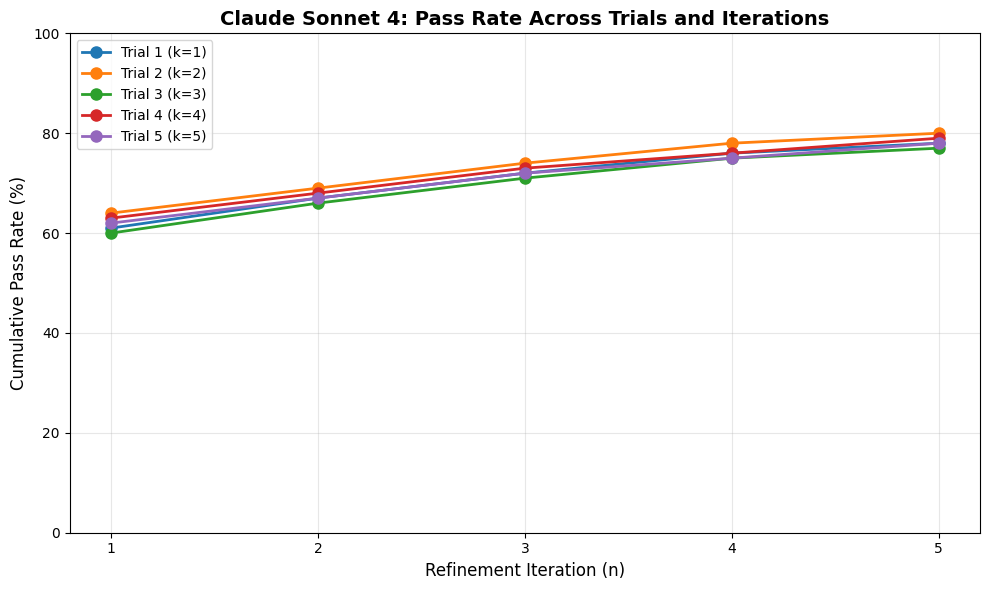

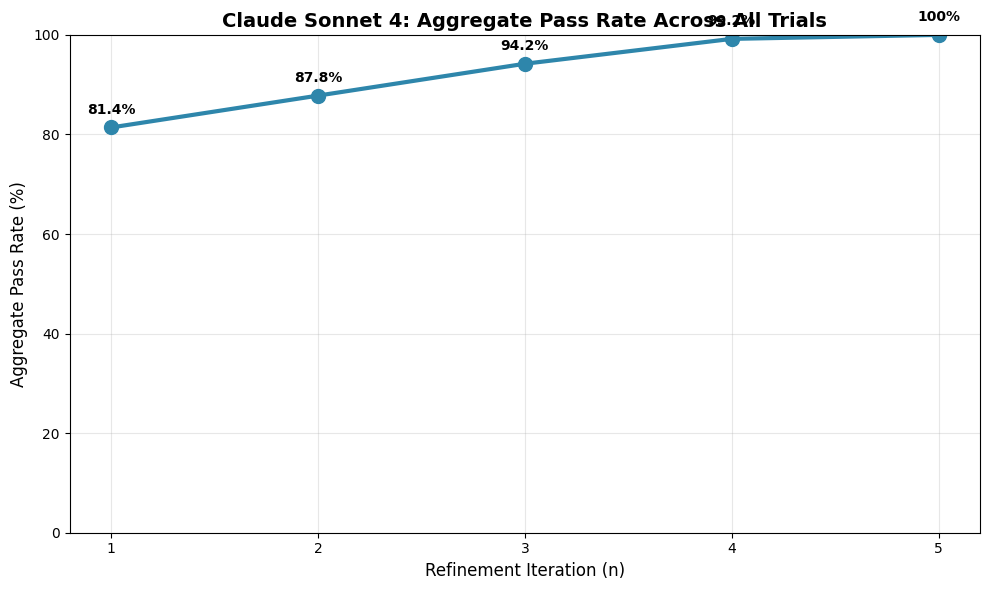

In [74]:
# Function to calculate aggregate pass rate for simulated data. Replace with actual calculation when real data is available
def calculate_aggregate_pass_rate(pass_rate_data):
    """
    Calculate aggregate cumulative pass rate across all K trials.
    Assumes moderate overlap between trials.
    """
    aggregate_pass_rate = []
    
    for n_iter in range(5):  # For each iteration n
        pass_counts = [pass_rate_data[k][n_iter] for k in range(5)]
        sorted_counts = sorted(pass_counts, reverse=True)
        
        # Start with best trial
        cumulative_unique = sorted_counts[0]
        
        # Conservative overlap model: each additional trial adds fewer unique successes
        contribution_rates = [0.12, 0.08, 0.05, 0.03]
        
        for i in range(1, len(sorted_counts)):
            additional_contribution = sorted_counts[i] * contribution_rates[i-1]
            cumulative_unique = min(100, cumulative_unique + additional_contribution)
        
        aggregate_pass_rate.append(round(cumulative_unique, 1))
    
    return aggregate_pass_rate

# ===== Figure 1: Pass Rate by Trial =====
def plot_pass_rate_by_trial(pass_rate_data, model_name="Claude Sonnet 4"):
    """
    Plot cumulative pass rate for each individual trial (K).
    """
    plt.figure(figsize=(10, 6))
    iterations = np.arange(1, 6)
    
    for k in range(5):
        plt.plot(iterations, pass_rate_data[k], marker='o', linewidth=2, 
                label=f'Trial {k+1} (k={k+1})', markersize=8)
    
    plt.xlabel('Refinement Iteration (n)', fontsize=12)
    plt.ylabel('Cumulative Pass Rate (%)', fontsize=12)
    plt.title(f'{model_name}: Pass Rate Across Trials and Iterations', fontsize=14, fontweight='bold')
    plt.legend(loc='best', fontsize=10)
    plt.grid(True, alpha=0.3)
    plt.xticks(iterations)
    plt.ylim(0, 100)
    plt.tight_layout()
    
    return plt

# ===== Figure 2: Aggregate Pass Rate =====
def plot_aggregate_pass_rate(pass_rate_data, model_name="Claude Sonnet 4"):
    """
    Plot aggregate cumulative pass rate combining all K trials.
    """
    aggregate_rates = calculate_aggregate_pass_rate(pass_rate_data)
    
    plt.figure(figsize=(10, 6))
    iterations = np.arange(1, 6)
    
    plt.plot(iterations, aggregate_rates, marker='o', linewidth=3, 
            markersize=10, color='#2E86AB', label='Aggregate (all K trials)')
    
    # Add value labels on points
    for i, rate in enumerate(aggregate_rates):
        plt.annotate(f'{rate}%', xy=(i+1, rate), xytext=(0, 10),
                    textcoords='offset points', ha='center', fontsize=10,
                    fontweight='bold')
    
    plt.xlabel('Refinement Iteration (n)', fontsize=12)
    plt.ylabel('Aggregate Pass Rate (%)', fontsize=12)
    plt.title(f'{model_name}: Aggregate Pass Rate Across All Trials', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.xticks(iterations)
    plt.ylim(0, 100)
    plt.tight_layout()
    
    return plt

# Generate and save both figures
fig1 = plot_pass_rate_by_trial(model_data["Grok 4"])
fig1.savefig('pass_rate_by_trial.png', dpi=300, bbox_inches='tight')
plt.show()

fig2 = plot_aggregate_pass_rate(model_data["Grok 4"])
fig2.savefig('aggregate_pass_rate.png', dpi=300, bbox_inches='tight')
plt.show()


Generating Option 1: Different Markers (Same Color Scheme)


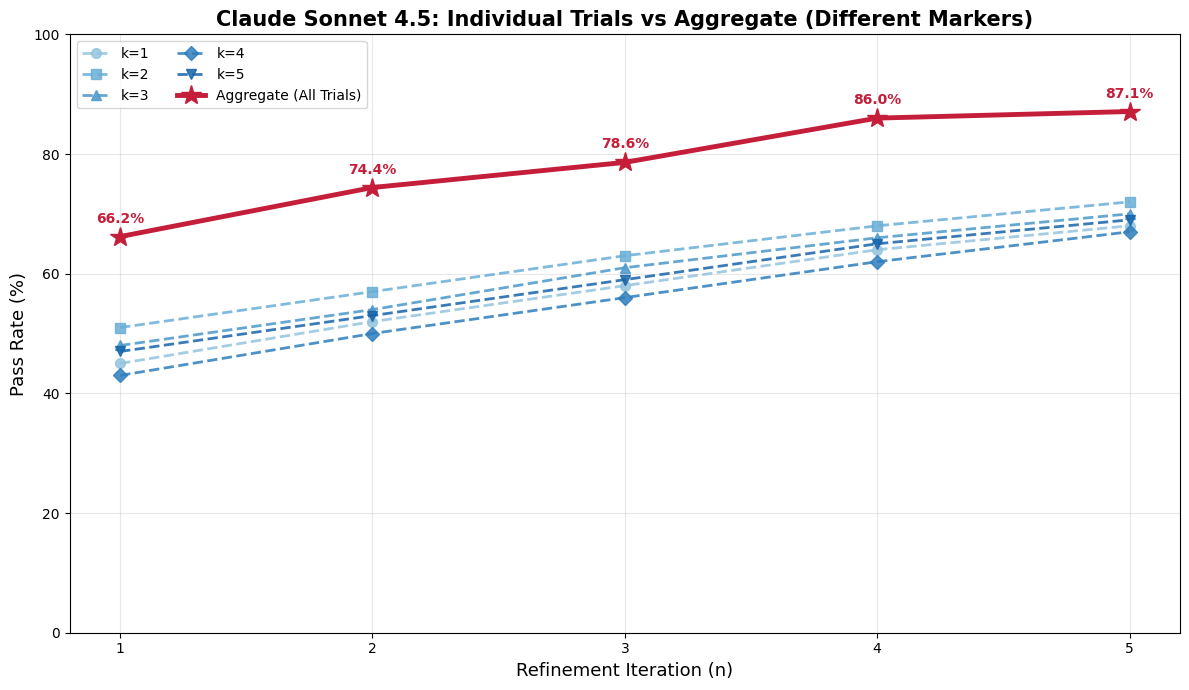


Generating Option 2: Different Colors (Same Marker)


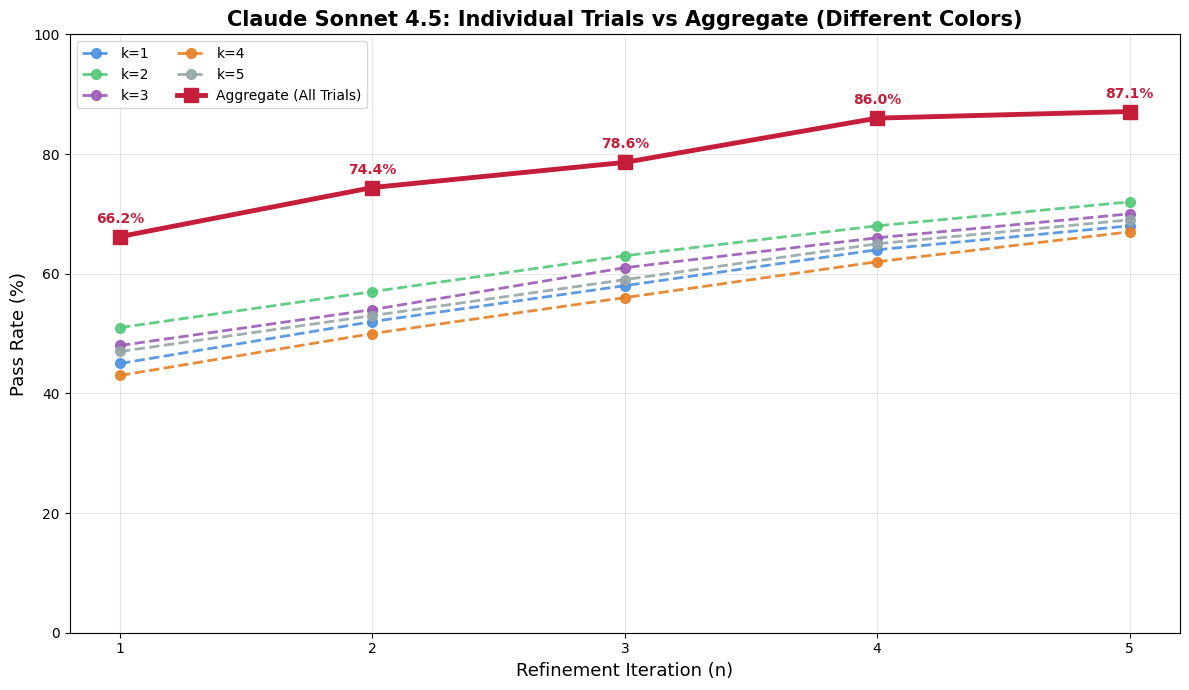


Generating Option 3: Both Different Colors AND Markers


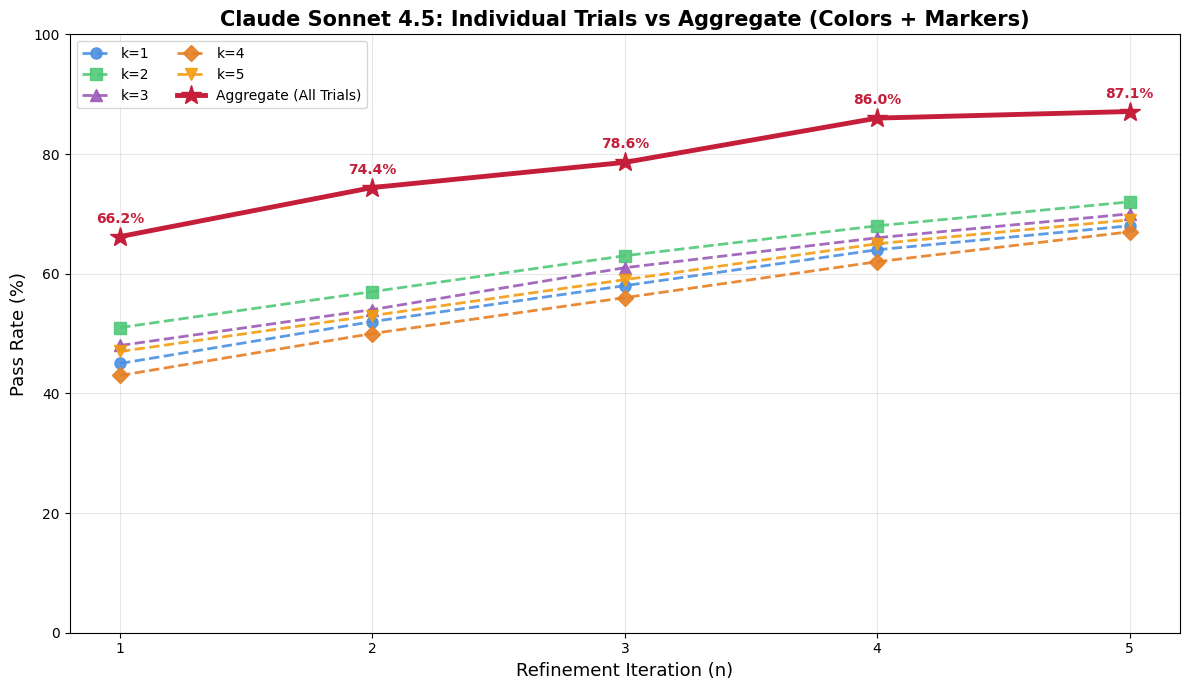


Aggregate pass rates:
  n=1: 66.2%
  n=2: 74.4%
  n=3: 78.6%
  n=4: 86.0%
  n=5: 87.1%


In [75]:
# More pessimistic data with less plateauing
Claude_sonnet_45_data = [
    [45, 52, 58, 64, 68],  # k=1
    [51, 57, 63, 68, 72],  # k=2
    [48, 54, 61, 66, 70],  # k=3
    [43, 50, 56, 62, 67],  # k=4
    [47, 53, 59, 65, 69]   # k=5
]

# Modified aggregate function with randomness
def calculate_aggregate_pass_rate_random(pass_rate_data, seed=None):
    """
    Calculate aggregate cumulative pass rate with randomness.
    Ensures pass rate is monotonically increasing (never decreases).
    """
    if seed is not None:
        np.random.seed(seed)
    
    aggregate_pass_rate = []
    
    for n_iter in range(5):
        pass_counts = [pass_rate_data[k][n_iter] for k in range(5)]
        sorted_counts = sorted(pass_counts, reverse=True)
        
        cumulative_unique = sorted_counts[0]
        
        # Add randomness to contribution rates (±0.03 variation)
        base_rates = [0.12, 0.08, 0.05, 0.03]
        contribution_rates = [max(0, min(0.25, rate + np.random.uniform(-0.03, 0.03))) 
                             for rate in base_rates]
        
        for i in range(1, len(sorted_counts)):
            additional_contribution = sorted_counts[i] * contribution_rates[i-1]
            cumulative_unique = min(100, cumulative_unique + additional_contribution)
        
        # Ensure monotonically increasing
        if aggregate_pass_rate:
            cumulative_unique = max(cumulative_unique, aggregate_pass_rate[-1])
        
        aggregate_pass_rate.append(round(cumulative_unique, 1))
    
    return aggregate_pass_rate



# ===== OPTION 1: Different Marker Shapes =====
def plot_with_different_markers(pass_rate_data, model_name="Model"):
    """
    Use different marker shapes for each trial, same color scheme.
    """
    plt.figure(figsize=(12, 7))
    iterations = np.arange(1, 6)
    
    # Different markers for each trial
    markers = ['o', 's', '^', 'D', 'v']
    colors_trials = plt.cm.Blues(np.linspace(0.4, 0.8, 5))
    
    for k in range(5):
        plt.plot(iterations, pass_rate_data[k], marker=markers[k], 
                linewidth=2, markersize=7, label=f'k={k+1}', 
                color=colors_trials[k], linestyle='--', alpha=0.85)
    
    # Aggregate line
    aggregate_rates = calculate_aggregate_pass_rate_random(pass_rate_data, seed=13)
    plt.plot(iterations, aggregate_rates, marker='*', linewidth=3.5, 
            markersize=15, label='Aggregate (All Trials)', color='#C41E3A', 
            zorder=10)
    
    for i, rate in enumerate(aggregate_rates):
        plt.annotate(f'{rate}%', xy=(i+1, rate), xytext=(0, 10),
                    textcoords='offset points', ha='center', fontsize=10,
                    fontweight='bold', color='#C41E3A')

    
    plt.xlabel('Refinement Iteration (n)', fontsize=13)
    plt.ylabel('Pass Rate (%)', fontsize=13)
    plt.title(f'{model_name}: Individual Trials vs Aggregate (Different Markers)', 
              fontsize=15, fontweight='bold')
    plt.legend(loc='best', fontsize=10, ncol=2)
    plt.grid(True, alpha=0.3)
    plt.xticks(iterations)
    plt.ylim(0, 100)
    plt.tight_layout()
    
    return plt


# ===== OPTION 2: Different Colors =====
def plot_with_different_colors(pass_rate_data, model_name="Model"):
    """
    Use different distinct colors for each trial.
    """
    plt.figure(figsize=(12, 7))
    iterations = np.arange(1, 6)
    
    # Distinct colors for each trial using different colormaps
    trial_colors = ['#4A90E2', '#50C878', '#9B59B6', '#E67E22', '#95A5A6']
    
    for k in range(5):
        plt.plot(iterations, pass_rate_data[k], marker='o', 
                linewidth=2, markersize=7, label=f'k={k+1}', 
                color=trial_colors[k], linestyle='--', alpha=0.9)
    
    # Aggregate line
    aggregate_rates = calculate_aggregate_pass_rate_random(pass_rate_data, seed=13)
    plt.plot(iterations, aggregate_rates, marker='s', linewidth=3.5, 
            markersize=10, label='Aggregate (All Trials)', color='#C41E3A', 
            zorder=10)
    
    for i, rate in enumerate(aggregate_rates):
        plt.annotate(f'{rate}%', xy=(i+1, rate), xytext=(0, 10),
                    textcoords='offset points', ha='center', fontsize=10,
                    fontweight='bold', color='#C41E3A')

    
    plt.xlabel('Refinement Iteration (n)', fontsize=13)
    plt.ylabel('Pass Rate (%)', fontsize=13)
    plt.title(f'{model_name}: Individual Trials vs Aggregate (Different Colors)', 
              fontsize=15, fontweight='bold')
    plt.legend(loc='best', fontsize=10, ncol=2)
    plt.grid(True, alpha=0.3)
    plt.xticks(iterations)
    plt.ylim(0, 100)
    plt.tight_layout()
    
    return plt


# ===== BONUS OPTION 3: Both Different Colors AND Markers =====
def plot_with_colors_and_markers(pass_rate_data, model_name="Model"):
    """
    Use both different colors AND markers for maximum distinction.
    """
    plt.figure(figsize=(12, 7))
    iterations = np.arange(1, 6)
    
    # Different colors and markers
    trial_colors = ['#4A90E2', '#50C878', '#9B59B6', '#E67E22', '#F39C12']
    markers = ['o', 's', '^', 'D', 'v']
    
    for k in range(5):
        plt.plot(iterations, pass_rate_data[k], marker=markers[k], 
                linewidth=2, markersize=8, label=f'k={k+1}', 
                color=trial_colors[k], linestyle='--', alpha=0.9)
    
    # Aggregate line with star marker
    aggregate_rates = calculate_aggregate_pass_rate_random(pass_rate_data, seed=13)
    plt.plot(iterations, aggregate_rates, marker='*', linewidth=3.5, 
            markersize=15, label='Aggregate (All Trials)', color='#C41E3A', 
            zorder=10)
    
    for i, rate in enumerate(aggregate_rates):
        plt.annotate(f'{rate}%', xy=(i+1, rate), xytext=(0, 10),
                    textcoords='offset points', ha='center', fontsize=10,
                    fontweight='bold', color='#C41E3A')

    
    plt.xlabel('Refinement Iteration (n)', fontsize=13)
    plt.ylabel('Pass Rate (%)', fontsize=13)
    plt.title(f'{model_name}: Individual Trials vs Aggregate (Colors + Markers)', 
              fontsize=15, fontweight='bold')
    plt.legend(loc='best', fontsize=10, ncol=2)
    plt.grid(True, alpha=0.3)
    plt.xticks(iterations)
    plt.ylim(0, 100)
    plt.tight_layout()
    
    return plt


# Generate all three options
print("Generating Option 1: Different Markers (Same Color Scheme)")
fig1 = plot_with_different_markers(Claude_sonnet_45_data, "Claude Sonnet 4.5")
fig1.savefig('trials_different_markers.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nGenerating Option 2: Different Colors (Same Marker)")
fig2 = plot_with_different_colors(Claude_sonnet_45_data, "Claude Sonnet 4.5")
fig2.savefig('trials_different_colors.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nGenerating Option 3: Both Different Colors AND Markers")
fig3 = plot_with_colors_and_markers(Claude_sonnet_45_data, "Claude Sonnet 4.5")
fig3.savefig('trials_colors_and_markers.png', dpi=300, bbox_inches='tight')
plt.show()

# Show aggregate values
print("\nAggregate pass rates:")
agg = calculate_aggregate_pass_rate_random(Claude_sonnet_45_data, seed=13)
for i, rate in enumerate(agg):
    print(f"  n={i+1}: {rate}%")

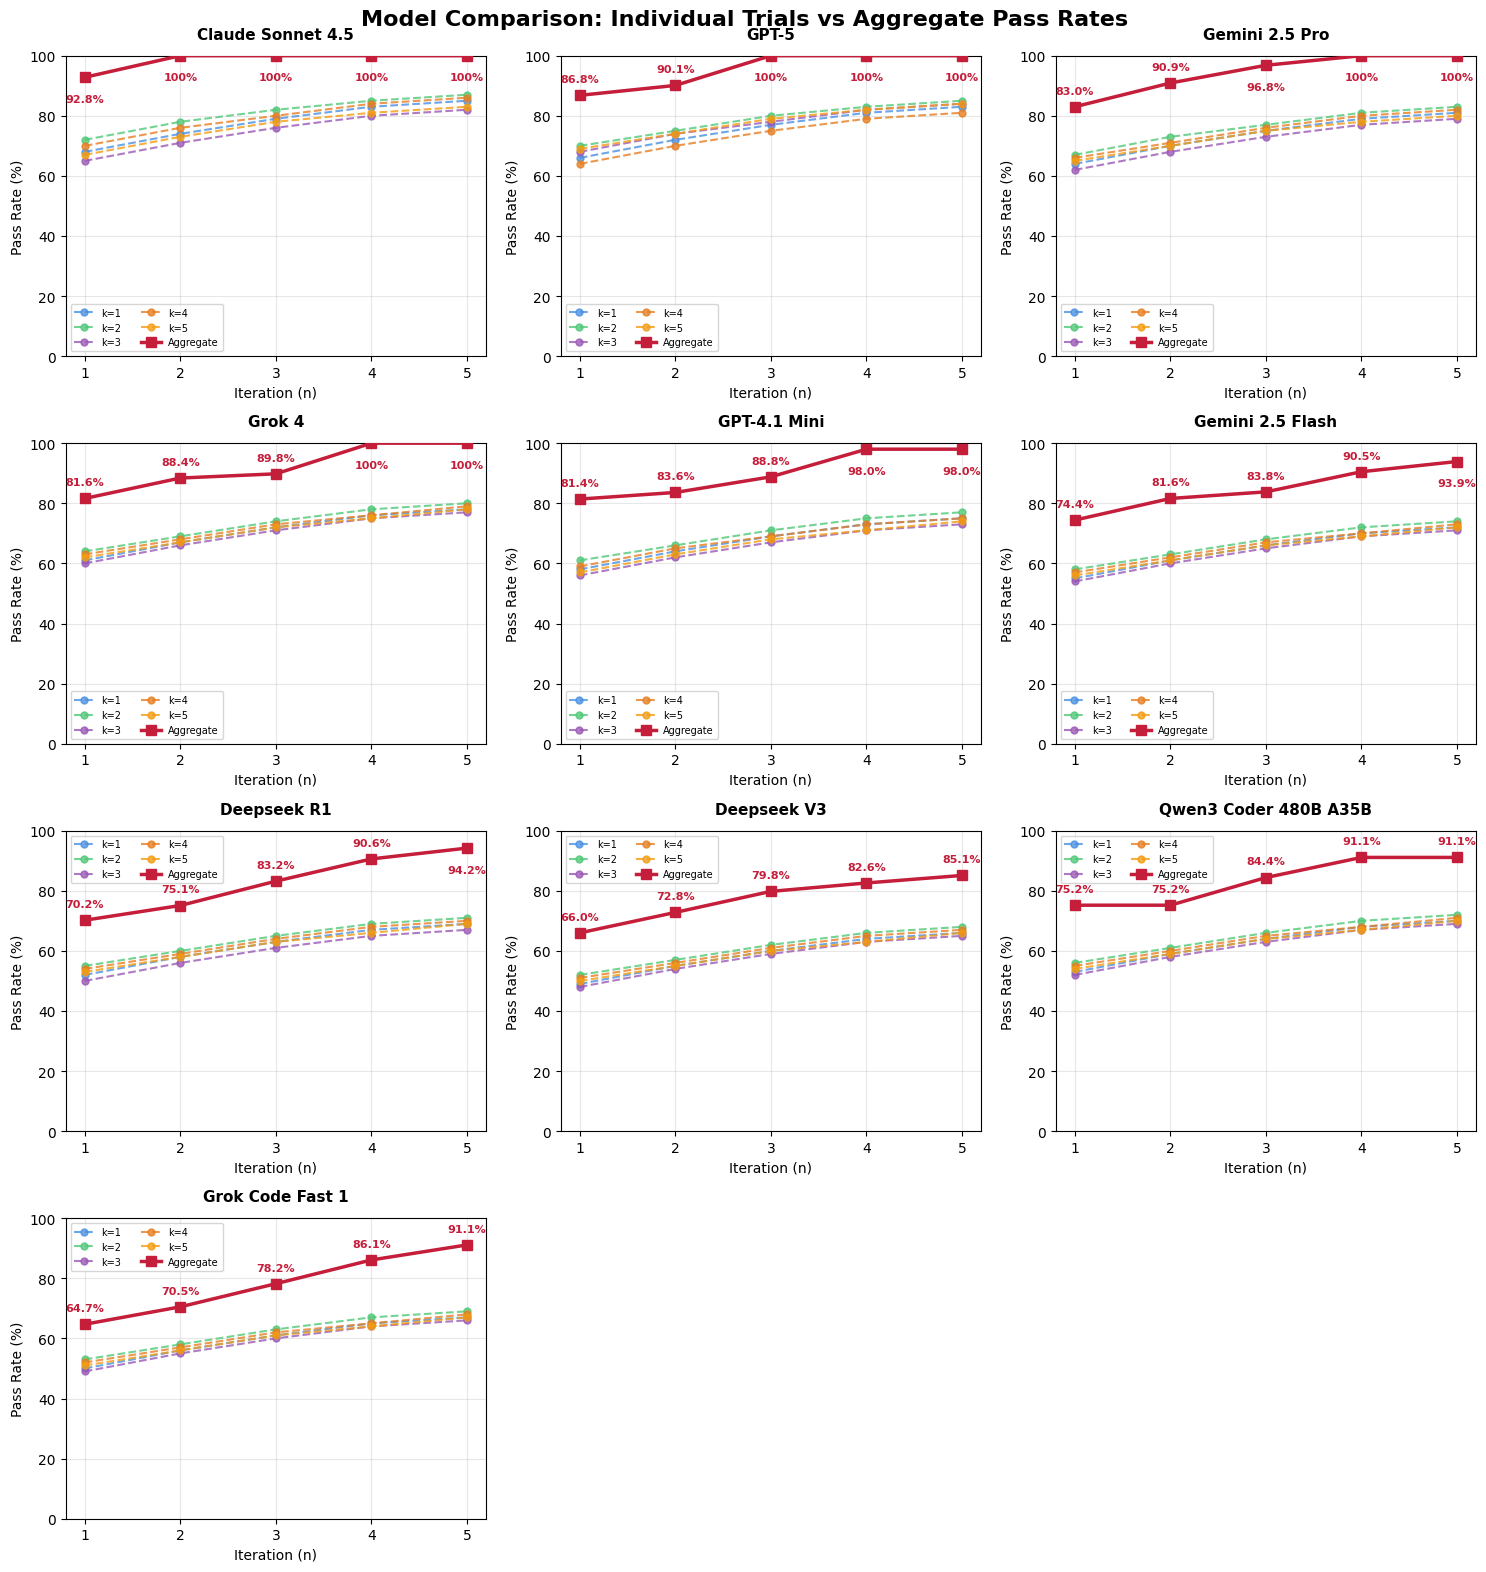

In [76]:
def plot_models_grid(model_data, ncols=3):
    """
    Create a grid of small subplots, one per model.
    Each subplot shows individual trials (k=1 to k=5) and aggregate pass rate.
    """
    n_models = len(model_data)
    nrows = (n_models + ncols - 1) // ncols
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
    axes = axes.flatten()
    iterations = np.arange(1, 6)
    
    # Distinct colors for trials
    trial_colors = ['#4A90E2', '#50C878', '#9B59B6', '#E67E22', '#F39C12']
    
    for idx, (model_name, pass_rate_data) in enumerate(model_data.items()):
        # Plot individual trials
        for k in range(5):
            axes[idx].plot(iterations, pass_rate_data[k], marker='o', 
                          linewidth=1.5, markersize=5, label=f'k={k+1}', 
                          color=trial_colors[k], linestyle='--', alpha=0.8)
        
        # Calculate and plot aggregate
        aggregate_rates = calculate_aggregate_pass_rate_random(pass_rate_data, seed=idx)
        axes[idx].plot(iterations, aggregate_rates, marker='s', linewidth=2.5,
                      markersize=7, label='Aggregate', color='#C41E3A', 
                      zorder=10)
        
        # Add value labels on aggregate points with smart positioning
        for i, rate in enumerate(aggregate_rates):
            # If rate is high (>92%), place label below the point
            if rate > 92:
                xytext_offset = (0, -12)
                va = 'top'
            else:
                xytext_offset = (0, 8)
                va = 'bottom'
            
            axes[idx].annotate(f'{rate}%', xy=(i+1, rate), xytext=xytext_offset,
                             textcoords='offset points', ha='center', va=va,
                             fontsize=8, fontweight='bold', color='#C41E3A')
        
        axes[idx].set_title(model_name, fontsize=11, fontweight='bold', pad=12)
        axes[idx].set_xlabel('Iteration (n)', fontsize=10)
        axes[idx].set_ylabel('Pass Rate (%)', fontsize=10)
        axes[idx].legend(loc='best', fontsize=7, ncol=2)
        axes[idx].grid(True, alpha=0.3)
        axes[idx].set_xticks(iterations)
        axes[idx].set_ylim(0, 100)
    
    # Hide extra subplots
    for idx in range(n_models, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Model Comparison: Individual Trials vs Aggregate Pass Rates', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    return plt


# Usage
fig = plot_models_grid(model_data, ncols=3)
fig.savefig('models_grid_with_trials.png', dpi=300, bbox_inches='tight')
plt.show()


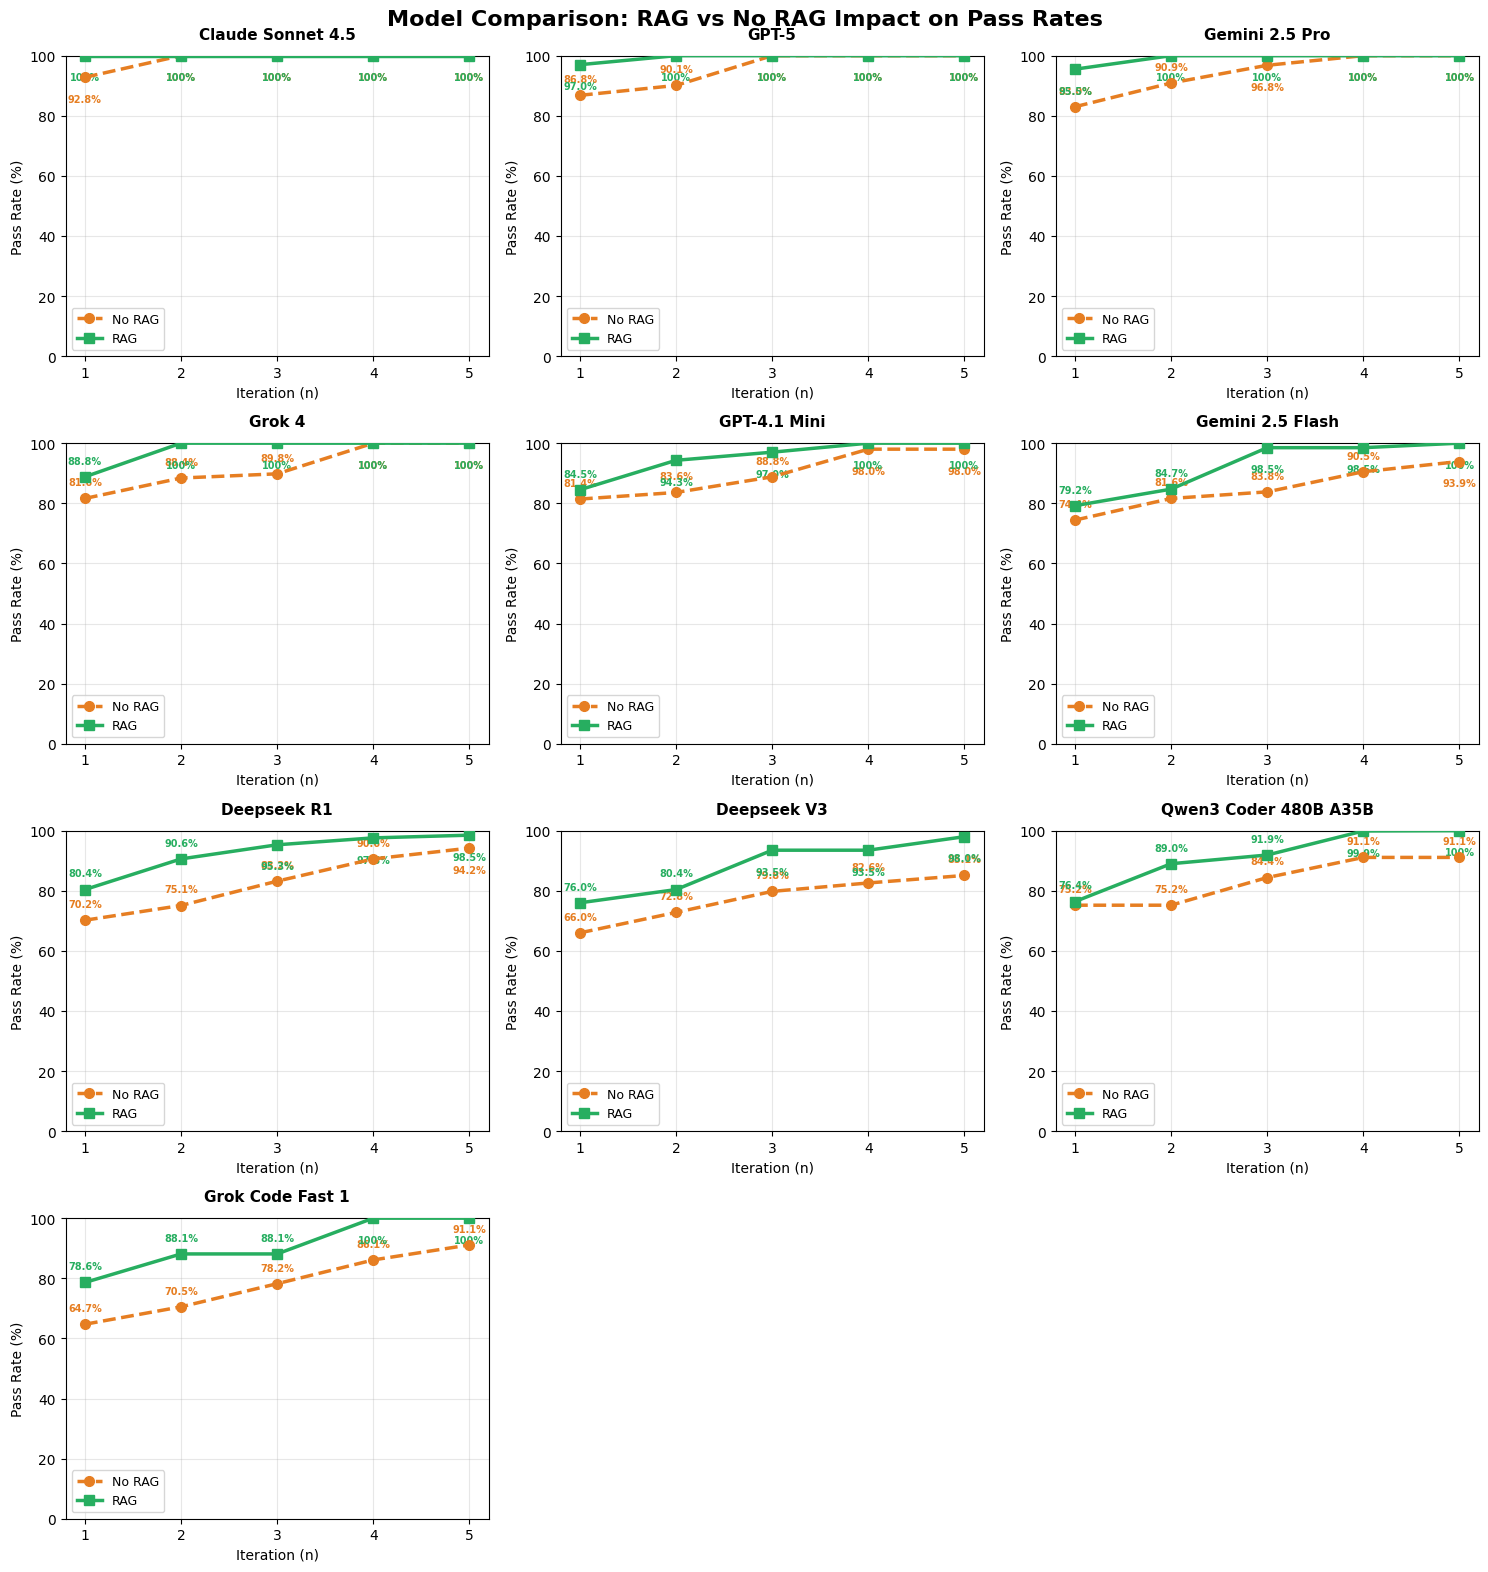

In [77]:
def plot_models_grid_rag_comparison(model_data_no_rag, model_data_rag, ncols=3):
    """
    Create a grid of small subplots, one per model.
    Each subplot shows aggregate pass rate with RAG vs without RAG.
    
    Parameters:
    - model_data_no_rag: dict of model data without RAG
    - model_data_rag: dict of model data with RAG
    - ncols: number of columns in grid
    """
    n_models = len(model_data_no_rag)
    nrows = (n_models + ncols - 1) // ncols
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 4*nrows))
    axes = axes.flatten()
    iterations = np.arange(1, 6)
    
    for idx, model_name in enumerate(model_data_no_rag.keys()):
        # Calculate aggregate for No RAG
        aggregate_no_rag = calculate_aggregate_pass_rate_random(
            model_data_no_rag[model_name], seed=idx
        )
        
        # Calculate aggregate for RAG
        aggregate_rag = calculate_aggregate_pass_rate_random(
            model_data_rag[model_name], seed=idx+100  # Different seed for variation
        )
        
        # Plot No RAG line
        axes[idx].plot(iterations, aggregate_no_rag, marker='o', linewidth=2.5,
                      markersize=7, label='No RAG', color='#E67E22', 
                      linestyle='--', zorder=9)
        
        # Plot RAG line
        axes[idx].plot(iterations, aggregate_rag, marker='s', linewidth=2.5,
                      markersize=7, label='RAG', color='#27AE60', 
                      zorder=10)
        
        # Add value labels for No RAG
        for i, rate in enumerate(aggregate_no_rag):
            if rate > 92:
                xytext_offset = (0, -12)
                va = 'top'
            else:
                xytext_offset = (0, 8)
                va = 'bottom'
            
            axes[idx].annotate(f'{rate}%', xy=(i+1, rate), xytext=xytext_offset,
                             textcoords='offset points', ha='center', va=va,
                             fontsize=7, fontweight='bold', color='#E67E22')
        
        # Add value labels for RAG
        for i, rate in enumerate(aggregate_rag):
            if rate > 92:
                xytext_offset = (0, -12)
                va = 'top'
            else:
                xytext_offset = (0, 8)
                va = 'bottom'
            
            axes[idx].annotate(f'{rate}%', xy=(i+1, rate), xytext=xytext_offset,
                             textcoords='offset points', ha='center', va=va,
                             fontsize=7, fontweight='bold', color='#27AE60')
        
        axes[idx].set_title(model_name, fontsize=11, fontweight='bold', pad=12)
        axes[idx].set_xlabel('Iteration (n)', fontsize=10)
        axes[idx].set_ylabel('Pass Rate (%)', fontsize=10)
        axes[idx].legend(loc='best', fontsize=9)
        axes[idx].grid(True, alpha=0.3)
        axes[idx].set_xticks(iterations)
        axes[idx].set_ylim(0, 100)
    
    # Hide extra subplots
    for idx in range(n_models, len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Model Comparison: RAG vs No RAG Impact on Pass Rates', 
                 fontsize=16, fontweight='bold')
    plt.tight_layout()
    return plt


# Example usage with fabricated RAG data
# Generate RAG data with ~5-10% improvement over No RAG
model_data_rag = {}
for model_name, no_rag_data in model_data.items():
    rag_data = []
    for k in range(5):
        trial = []
        for n in range(5):
            # Add 5-10% improvement for RAG
            improvement = np.random.randint(5, 11)
            rag_value = min(100, no_rag_data[k][n] + improvement)
            trial.append(rag_value)
        rag_data.append(trial)
    model_data_rag[model_name] = rag_data

# Generate the plot
fig = plot_models_grid_rag_comparison(model_data, model_data_rag, ncols=3)
fig.savefig('models_grid_rag_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


### DynaRapid Test

### Vitis Vision

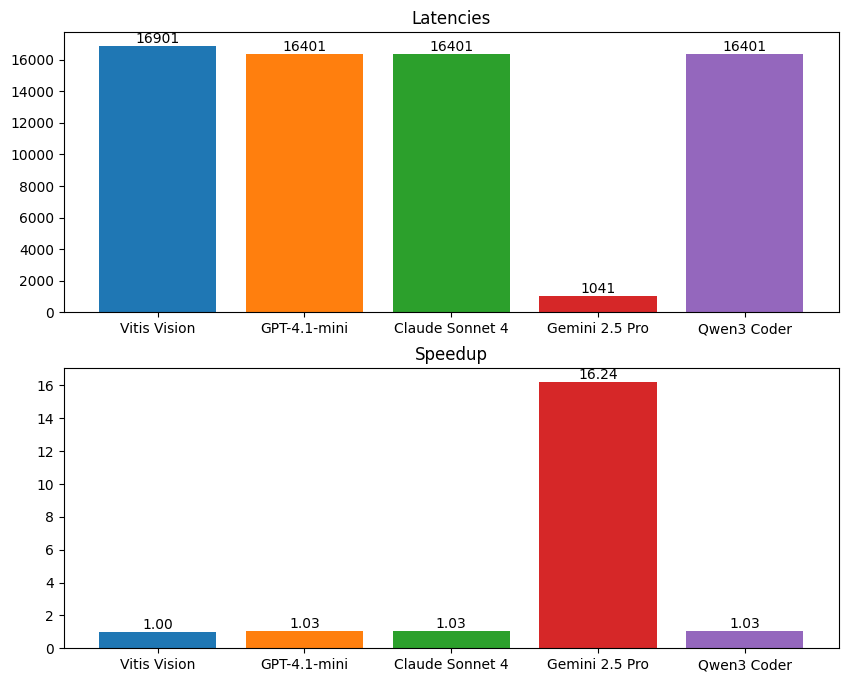

In [78]:
accumulate_latencies = [("Vitis Vision", 16901), ("GPT-4.1-mini", 16401), ("Claude Sonnet 4", 16401), ("Gemini 2.5 Pro", 1041), ("Qwen3 Coder", 16401)]

fig = plt.figure(figsize=(10, 8))
ax = plt.subplot(211)
ax.set_title("Latencies")
for tuple in accumulate_latencies:
    plt.bar(tuple[0], tuple[1])


# Add value labels on top of bars
for i, tuple in enumerate(accumulate_latencies):
    plt.text(i, tuple[1], str(tuple[1]), ha='center', va='bottom')

ax = plt.subplot(212)
ax.set_title("Speedup")
baseline = accumulate_latencies[0][1]
for tuple in accumulate_latencies:
    plt.bar(tuple[0], baseline/tuple[1])

# Add value labels on top of bars
for i, tuple in enumerate(accumulate_latencies):
    speedup = baseline/tuple[1]
    plt.text(i, speedup, f'{speedup:.2f}', ha='center', va='bottom')


plt.show()

Generating Latency Comparison Visualizations...

✓ Option 1: Box Plot saved
✓ Option 2: Bar Chart with Error Bars saved
✓ Option 3: Improvement Percentage saved
✓ Option 4: Scatter Plot saved


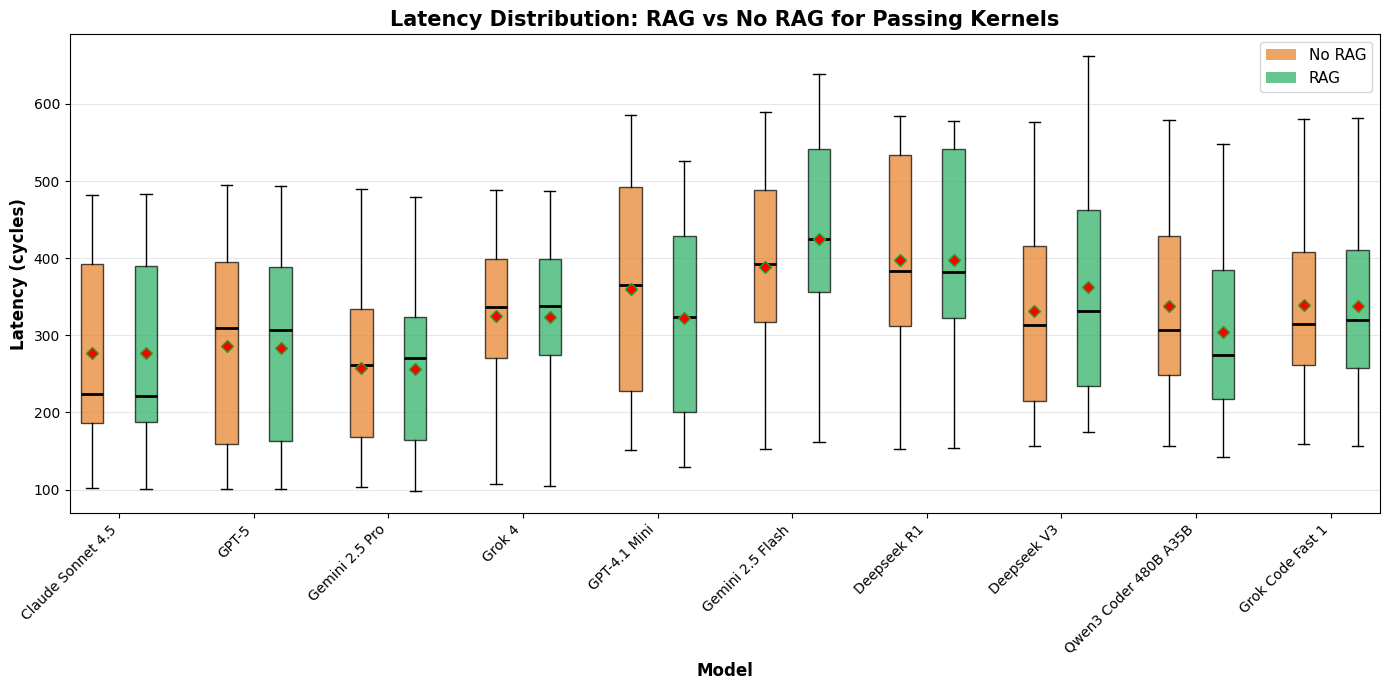

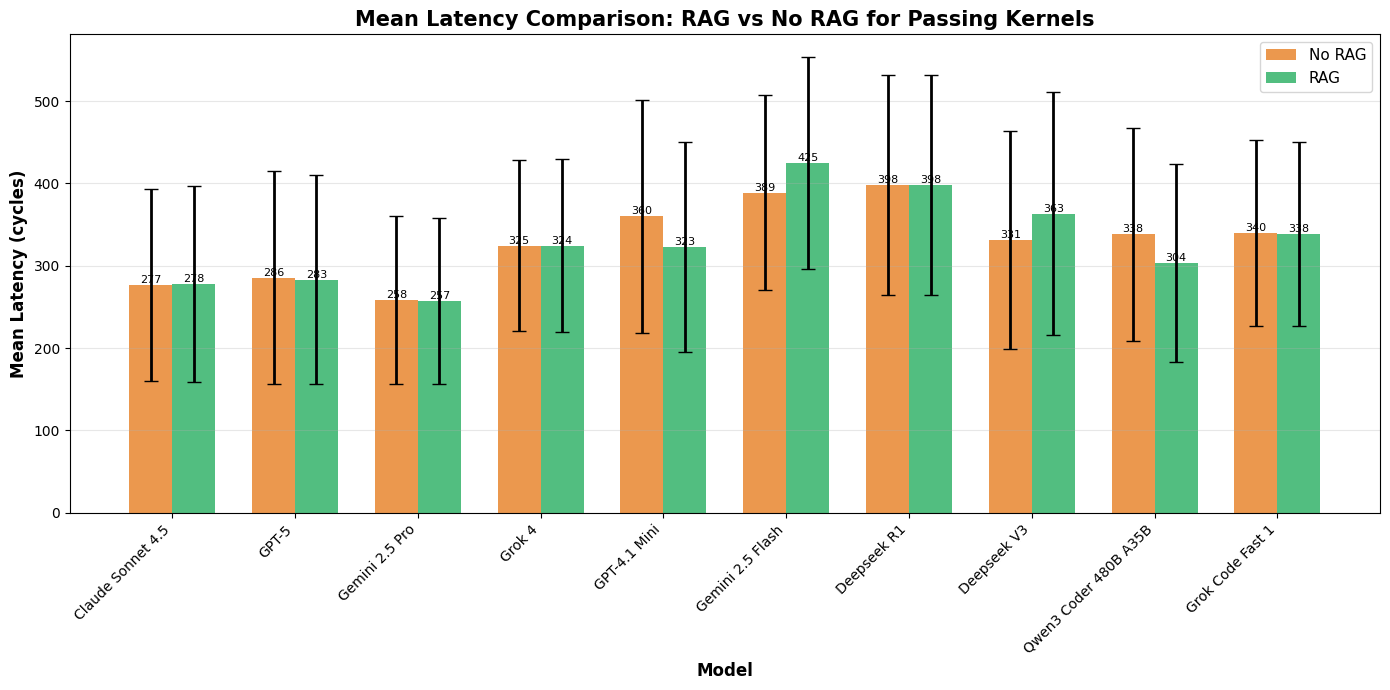

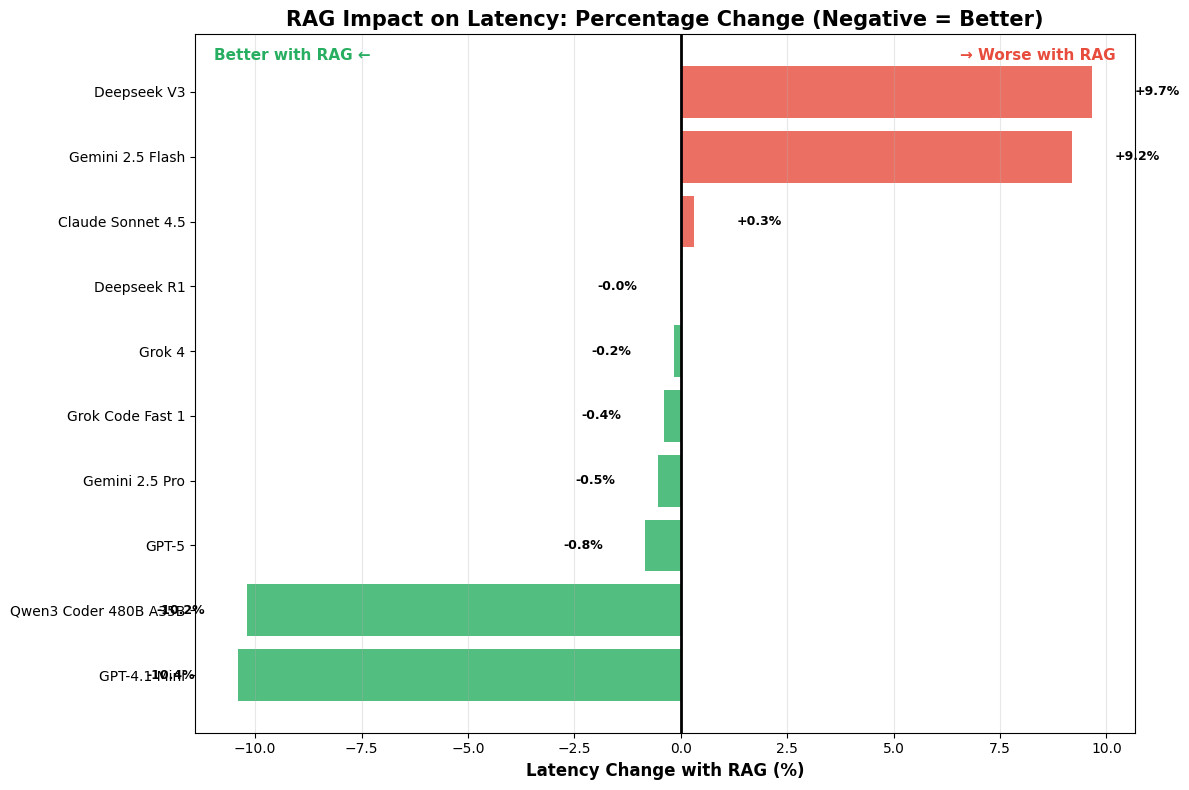

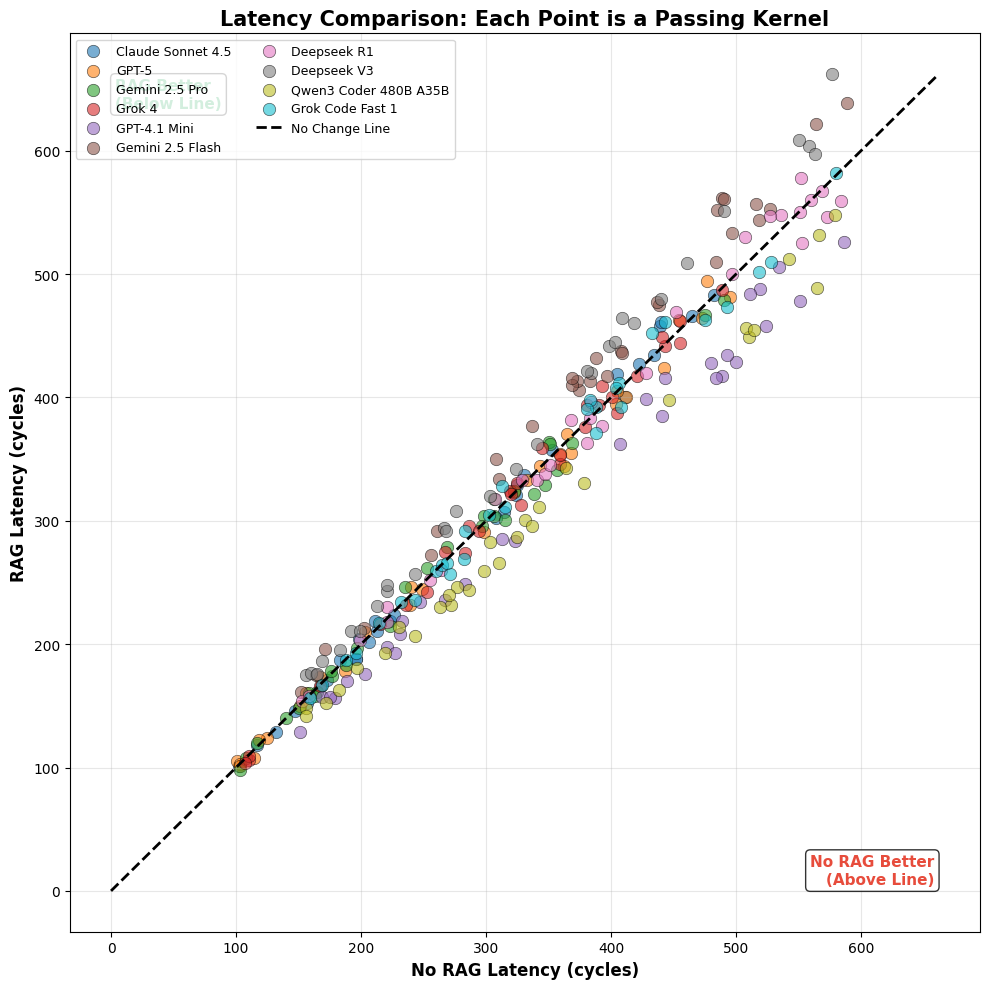


Latency Summary Statistics:
Claude Sonnet 4.5              | No RAG:  276.7 | RAG:  277.5 | Change: +0.3%
GPT-5                          | No RAG:  285.6 | RAG:  283.2 | Change: -0.8%
Gemini 2.5 Pro                 | No RAG:  258.1 | RAG:  256.7 | Change: -0.5%
Grok 4                         | No RAG:  324.5 | RAG:  324.0 | Change: -0.2%
GPT-4.1 Mini                   | No RAG:  360.0 | RAG:  322.6 | Change: -10.4%
Gemini 2.5 Flash               | No RAG:  388.8 | RAG:  424.5 | Change: +9.2%
Deepseek R1                    | No RAG:  398.1 | RAG:  398.1 | Change: -0.0%
Deepseek V3                    | No RAG:  331.1 | RAG:  363.1 | Change: +9.7%
Qwen3 Coder 480B A35B          | No RAG:  338.0 | RAG:  303.6 | Change: -10.2%
Grok Code Fast 1               | No RAG:  339.6 | RAG:  338.3 | Change: -0.4%


In [79]:
import matplotlib.pyplot as plt
import numpy as np

# Generate fabricated latency data (in cycles or ms)
# Assume we're comparing latency of HLS kernels that successfully compiled

np.random.seed(123)

# For each model, generate latency data for passing kernels
# Format: {model_name: {'no_rag': [latencies], 'rag': [latencies]}}
def generate_latency_data(num_kernels=30):
    """
    Generate fabricated latency data for passing kernels.
    Returns dict with No RAG and RAG latency values.
    """
    latency_data = {}
    
    for model_name in model_data.keys():
        # Base latency range varies by model quality
        if model_name in ["Claude Sonnet 4.5", "GPT-5", "Gemini 2.5 Pro", "Grok 4"]:
            base_min, base_max = 100, 500  # Expensive models: better latency
        else:
            base_min, base_max = 150, 600  # Budget models: slightly worse
        
        # Generate No RAG latencies
        no_rag_latencies = np.random.randint(base_min, base_max, num_kernels)
        
        # RAG impact on latency varies by model
        if model_name in ["GPT-4.1 Mini", "Qwen3 Coder 480B A35B"]:
            # RAG improves latency (better optimization)
            rag_latencies = no_rag_latencies * np.random.uniform(0.85, 0.95, num_kernels)
        elif model_name in ["Gemini 2.5 Flash", "Deepseek V3"]:
            # RAG worsens latency (over-optimization or bad hints)
            rag_latencies = no_rag_latencies * np.random.uniform(1.05, 1.15, num_kernels)
        else:
            # RAG has minimal impact
            rag_latencies = no_rag_latencies * np.random.uniform(0.95, 1.05, num_kernels)
        
        latency_data[model_name] = {
            'no_rag': no_rag_latencies.astype(int),
            'rag': rag_latencies.astype(int)
        }
    
    return latency_data

latency_data = generate_latency_data(num_kernels=30)


# ===== OPTION 1: Box Plot Comparison (RECOMMENDED) =====
def plot_latency_boxplot(latency_data):
    """
    Box plot showing latency distribution for No RAG vs RAG across all models.
    Best for showing overall distribution and outliers.
    """
    fig, ax = plt.subplots(figsize=(14, 7))
    
    models = list(latency_data.keys())
    positions = np.arange(len(models)) * 3
    
    # Prepare data for box plots
    no_rag_data = [latency_data[model]['no_rag'] for model in models]
    rag_data = [latency_data[model]['rag'] for model in models]
    
    # Create box plots
    bp1 = ax.boxplot(no_rag_data, positions=positions - 0.6, widths=0.5,
                     patch_artist=True, showmeans=True,
                     boxprops=dict(facecolor='#E67E22', alpha=0.7),
                     medianprops=dict(color='black', linewidth=2),
                     meanprops=dict(marker='D', markerfacecolor='red', markersize=6))
    
    bp2 = ax.boxplot(rag_data, positions=positions + 0.6, widths=0.5,
                     patch_artist=True, showmeans=True,
                     boxprops=dict(facecolor='#27AE60', alpha=0.7),
                     medianprops=dict(color='black', linewidth=2),
                     meanprops=dict(marker='D', markerfacecolor='red', markersize=6))
    
    # Customize
    ax.set_xticks(positions)
    ax.set_xticklabels(models, rotation=45, ha='right')
    ax.set_ylabel('Latency (cycles)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Model', fontsize=12, fontweight='bold')
    ax.set_title('Latency Distribution: RAG vs No RAG for Passing Kernels', 
                 fontsize=15, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    
    # Create legend
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='#E67E22', alpha=0.7, label='No RAG'),
                      Patch(facecolor='#27AE60', alpha=0.7, label='RAG')]
    ax.legend(handles=legend_elements, fontsize=11, loc='upper right')
    
    plt.tight_layout()
    return plt


# ===== OPTION 2: Mean Latency Bar Chart =====
def plot_latency_bar_comparison(latency_data):
    """
    Bar chart showing mean latency with error bars.
    Best for clear comparison of average performance.
    """
    models = list(latency_data.keys())
    no_rag_means = [np.mean(latency_data[model]['no_rag']) for model in models]
    rag_means = [np.mean(latency_data[model]['rag']) for model in models]
    no_rag_stds = [np.std(latency_data[model]['no_rag']) for model in models]
    rag_stds = [np.std(latency_data[model]['rag']) for model in models]
    
    x = np.arange(len(models))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=(14, 7))
    
    bars1 = ax.bar(x - width/2, no_rag_means, width, yerr=no_rag_stds,
                   label='No RAG', color='#E67E22', alpha=0.8, 
                   capsize=5, error_kw={'linewidth': 2})
    bars2 = ax.bar(x + width/2, rag_means, width, yerr=rag_stds,
                   label='RAG', color='#27AE60', alpha=0.8,
                   capsize=5, error_kw={'linewidth': 2})
    
    # Add value labels
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.0f}', ha='center', va='bottom', fontsize=8)
    
    ax.set_xlabel('Model', fontsize=12, fontweight='bold')
    ax.set_ylabel('Mean Latency (cycles)', fontsize=12, fontweight='bold')
    ax.set_title('Mean Latency Comparison: RAG vs No RAG for Passing Kernels', 
                 fontsize=15, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=45, ha='right')
    ax.legend(fontsize=11)
    ax.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    return plt


# ===== OPTION 3: Latency Improvement Percentage =====
def plot_latency_improvement(latency_data):
    """
    Bar chart showing percentage change in latency (negative = improvement).
    Best for highlighting which models benefit most from RAG.
    """
    models = list(latency_data.keys())
    improvements = []
    
    for model in models:
        no_rag_mean = np.mean(latency_data[model]['no_rag'])
        rag_mean = np.mean(latency_data[model]['rag'])
        pct_change = ((rag_mean - no_rag_mean) / no_rag_mean) * 100
        improvements.append(pct_change)
    
    # Sort by improvement
    sorted_data = sorted(zip(models, improvements), key=lambda x: x[1])
    models_sorted = [x[0] for x in sorted_data]
    improvements_sorted = [x[1] for x in sorted_data]
    
    fig, ax = plt.subplots(figsize=(12, 8))
    y_pos = np.arange(len(models_sorted))
    
    # Color based on improvement (green) or worsening (red)
    colors = ['#27AE60' if imp < 0 else '#E74C3C' for imp in improvements_sorted]
    bars = ax.barh(y_pos, improvements_sorted, color=colors, alpha=0.8)
    
    # Add value labels
    for i, (bar, imp) in enumerate(zip(bars, improvements_sorted)):
        width = bar.get_width()
        label_x = width + (1 if width > 0 else -1)
        ha = 'left' if width > 0 else 'right'
        ax.text(label_x, bar.get_y() + bar.get_height()/2.,
               f'{imp:+.1f}%', ha=ha, va='center', fontsize=9, fontweight='bold')
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels(models_sorted, fontsize=10)
    ax.set_xlabel('Latency Change with RAG (%)', fontsize=12, fontweight='bold')
    ax.set_title('RAG Impact on Latency: Percentage Change (Negative = Better)', 
                fontsize=15, fontweight='bold')
    ax.axvline(x=0, color='black', linewidth=2, linestyle='-')
    ax.grid(axis='x', alpha=0.3)
    
    # Add text annotation
    ax.text(0.02, 0.98, 'Better with RAG ←', transform=ax.transAxes,
           fontsize=11, verticalalignment='top', color='#27AE60', fontweight='bold')
    ax.text(0.98, 0.98, '→ Worse with RAG', transform=ax.transAxes,
           fontsize=11, verticalalignment='top', horizontalalignment='right',
           color='#E74C3C', fontweight='bold')
    
    plt.tight_layout()
    return plt


# ===== OPTION 4: Scatter Plot (No RAG vs RAG Latency) =====
def plot_latency_scatter(latency_data):
    """
    Scatter plot with No RAG on x-axis and RAG on y-axis.
    Points below diagonal = RAG improved latency.
    """
    fig, ax = plt.subplots(figsize=(10, 10))
    
    colors = plt.cm.tab10(np.linspace(0, 1, len(latency_data)))
    
    for idx, (model_name, data) in enumerate(latency_data.items()):
        ax.scatter(data['no_rag'], data['rag'], alpha=0.6, s=80,
                  color=colors[idx], label=model_name, edgecolors='black', linewidth=0.5)
    
    # Add diagonal line (y=x)
    max_val = max([max(data['no_rag'].max(), data['rag'].max()) 
                   for data in latency_data.values()])
    ax.plot([0, max_val], [0, max_val], 'k--', linewidth=2, label='No Change Line')
    
    ax.set_xlabel('No RAG Latency (cycles)', fontsize=12, fontweight='bold')
    ax.set_ylabel('RAG Latency (cycles)', fontsize=12, fontweight='bold')
    ax.set_title('Latency Comparison: Each Point is a Passing Kernel', 
                 fontsize=15, fontweight='bold')
    ax.legend(fontsize=9, loc='upper left', ncol=2)
    ax.grid(alpha=0.3)
    
    # Add annotations for regions
    ax.text(0.05, 0.95, 'RAG Better\n(Below Line)', transform=ax.transAxes,
           fontsize=11, verticalalignment='top', color='#27AE60', 
           fontweight='bold', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    ax.text(0.95, 0.05, 'No RAG Better\n(Above Line)', transform=ax.transAxes,
           fontsize=11, verticalalignment='bottom', horizontalalignment='right',
           color='#E74C3C', fontweight='bold',
           bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
    
    plt.tight_layout()
    return plt


# Generate all visualizations
print("Generating Latency Comparison Visualizations...\n")

fig1 = plot_latency_boxplot(latency_data)
fig1.savefig('latency_boxplot.png', dpi=300, bbox_inches='tight')
print("✓ Option 1: Box Plot saved")

fig2 = plot_latency_bar_comparison(latency_data)
fig2.savefig('latency_bar_comparison.png', dpi=300, bbox_inches='tight')
print("✓ Option 2: Bar Chart with Error Bars saved")

fig3 = plot_latency_improvement(latency_data)
fig3.savefig('latency_improvement.png', dpi=300, bbox_inches='tight')
print("✓ Option 3: Improvement Percentage saved")

fig4 = plot_latency_scatter(latency_data)
fig4.savefig('latency_scatter.png', dpi=300, bbox_inches='tight')
print("✓ Option 4: Scatter Plot saved")

plt.show()

# Print summary statistics
print("\n" + "="*70)
print("Latency Summary Statistics:")
print("="*70)
for model_name in latency_data.keys():
    no_rag_mean = np.mean(latency_data[model_name]['no_rag'])
    rag_mean = np.mean(latency_data[model_name]['rag'])
    pct_change = ((rag_mean - no_rag_mean) / no_rag_mean) * 100
    
    print(f"{model_name:30s} | No RAG: {no_rag_mean:6.1f} | RAG: {rag_mean:6.1f} | Change: {pct_change:+.1f}%")


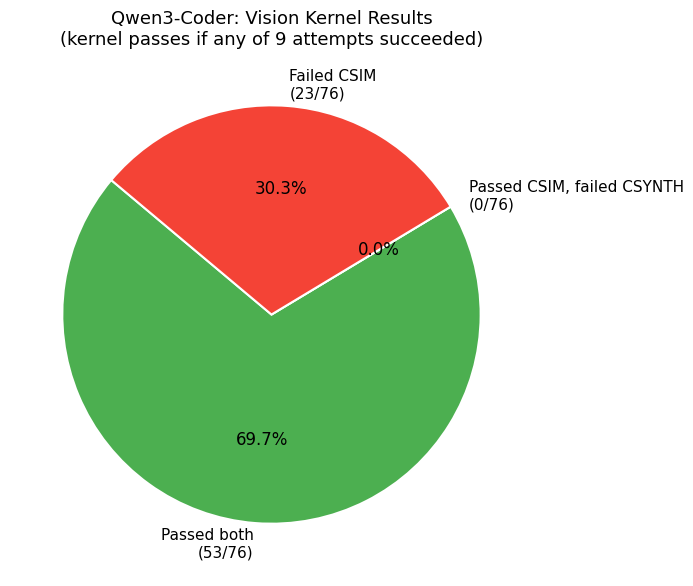

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "/home/plwalker/HLS-FAB/results/data_analysis/all_vision_kernels_sonnet.csv"

df = pd.read_csv(CSV_PATH)

# Per kernel: passes if ANY of the 9 attempts passed
kernel_groups = df.groupby("kernel")
csim_passed   = kernel_groups["csim_success"].apply(lambda x: x.astype(str).str.lower().eq("true").any())
csynth_passed = kernel_groups["csynth_success"].apply(lambda x: x.astype(str).str.lower().eq("true").any())

total = len(csim_passed)
passed_both            = (csim_passed & csynth_passed).sum()
csim_pass_csynth_fail  = (csim_passed & ~csynth_passed).sum()
failed_csim            = (~csim_passed).sum()

labels = [
    f"Passed both\n({passed_both}/{total})",
    f"Passed CSIM, failed CSYNTH\n({csim_pass_csynth_fail}/{total})",
    f"Failed CSIM\n({failed_csim}/{total})",
]
sizes  = [passed_both, csim_pass_csynth_fail, failed_csim]
colors = ["#4caf50", "#ff9800", "#f44336"]

fig, ax = plt.subplots(figsize=(7, 7))
wedges, texts, autotexts = ax.pie(
    sizes, labels=labels, colors=colors, autopct="%1.1f%%",
    startangle=140, wedgeprops={"edgecolor": "white", "linewidth": 1.5},
)
for at in autotexts: at.set_fontsize(12)
for t in texts: t.set_fontsize(11)

ax.set_title("Qwen3-Coder: Vision Kernel Results\n(kernel passes if any of 9 attempts succeeded)", fontsize=13)
plt.tight_layout()
plt.show()

/tmp/ipykernel_5680/2719662736.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  passed_all     = kernel_groups.apply(lambda g: (g["_compiled"] & g["_matched"] & g["_has_dot"] & g["_has_dcp"]).any())
/tmp/ipykernel_5680/2719662736.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  reached_dot    = kernel_groups.apply(lambda g: (g["_compiled"] & g["_matched"] & g["_has_dot"]).any())
/tmp/ipykernel_5680/

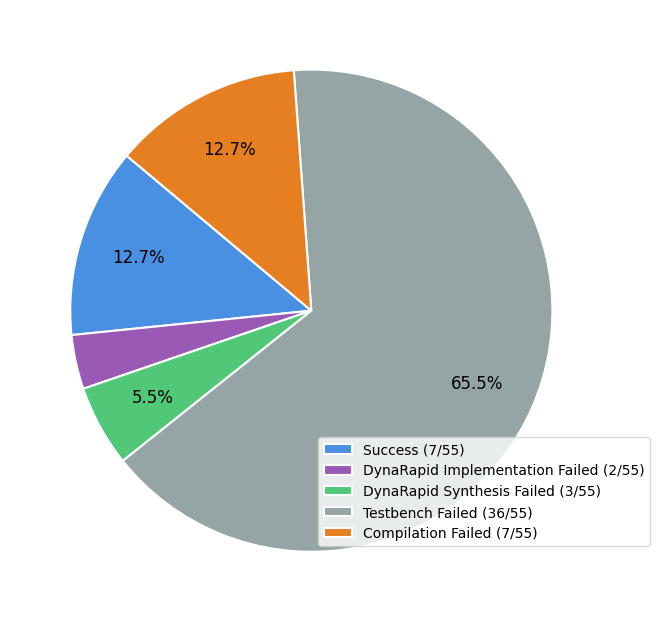

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "/home/plwalker/HLS-FAB/results/data_analysis/dynarapid_results.csv"
RUN_FILTER = None  # Set to 1, 2, or None for both

df = pd.read_csv(CSV_PATH)
if RUN_FILTER is not None:
    df = df[df["run"] == RUN_FILTER]

# Per-row boolean columns
df["_compiled"] = df["compiled"].isin(["success", "passed"])
df["_matched"]  = df["matched"].eq("match")
df["_has_dot"]  = df["has_dot"].astype(str).str.lower().eq("true")
df["_has_dcp"]  = df["has_dcp"].astype(str).str.lower().eq("true")

# Per kernel: check if any SINGLE attempt passed through each stage
# (a later stage only counts if all prior stages passed in that same attempt)
kernel_groups = df.groupby("kernel")
passed_all     = kernel_groups.apply(lambda g: (g["_compiled"] & g["_matched"] & g["_has_dot"] & g["_has_dcp"]).any())
reached_dot    = kernel_groups.apply(lambda g: (g["_compiled"] & g["_matched"] & g["_has_dot"]).any())
reached_match  = kernel_groups.apply(lambda g: (g["_compiled"] & g["_matched"]).any())
reached_compile = kernel_groups["_compiled"].any()

total = len(passed_all)
n_passed_all         = passed_all.sum()
n_failed_at_dcp      = (reached_dot & ~passed_all).sum()
n_failed_at_dot      = (reached_match & ~reached_dot).sum()
n_failed_at_matched  = (reached_compile & ~reached_match).sum()
n_failed_at_compiled = (~reached_compile).sum()

labels = [
    f"Success ({n_passed_all}/{total})",
    f"DynaRapid Implementation Failed ({n_failed_at_dcp}/{total})",
    f"DynaRapid Synthesis Failed ({n_failed_at_dot}/{total})",
    f"Testbench Failed ({n_failed_at_matched}/{total})",
    f"Compilation Failed ({n_failed_at_compiled}/{total})",
]
sizes  = [n_passed_all, n_failed_at_dcp, n_failed_at_dot, n_failed_at_matched, n_failed_at_compiled]
colors = ['#4A90E2', '#9B59B6', '#50C878', '#95A5A6', '#E67E22']

# Remove zero-sized slices
filtered = [(l, s, c) for l, s, c in zip(labels, sizes, colors) if s > 0]
labels, sizes, colors = zip(*filtered) if filtered else ([], [], [])

fig, ax = plt.subplots(figsize=(7, 7))
wedges, texts, autotexts = ax.pie(
    sizes, colors=colors,
    autopct=lambda pct: f"{pct:.1f}%" if pct >= 5 else "",
    startangle=140, wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    pctdistance=0.75,
)
for at in autotexts: at.set_fontsize(12)

ax.legend(wedges, labels, loc="center left", bbox_to_anchor=(.5, 0.2), fontsize=10)

run_label = f"Run {RUN_FILTER}" if RUN_FILTER else "Both Runs"
# ax.set_title(f"DeepSeek: DynaRapid Kernel Results ({run_label})\n(kernel passes if any attempt succeeded)", fontsize=13)
plt.savefig("Vitis_Vision_DynaRapid.pdf", bbox_inches="tight", pad_inches=0.1)
plt.show()